# Experiments 8 & 9 — Effect of Attention Type and Attention Position in a Pretrained ResNet50
**CS3807 – Deep Learning Laboratory** | Dataset: TensorFlow Flowers (5 classes) | Seed: **109**

**How to run:** Kaggle → set *Accelerator = GPU* and *Internet = On* → **Save Version → Save & Run All (Commit)**. The commit runs headless on Kaggle's servers, so closing the laptop does not stop it.

**Protocol (identical for every run):** same 70/15/15 stratified split (indices saved to JSON), same augmentation, Adam, batch 32, 10 epochs frozen backbone (lr 1e-3) + 10 epochs fine-tuning of conv5 (lr 1e-4), same classifier (GAP → Dropout 0.3 → Dense 5), constant learning rate, final-epoch weights evaluated.

**Position naming (manual §7):** P1 = after conv2_x, P2 = after conv3_x, P3 = after conv4_x, P4 = after conv5_x.

**16 training runs:** A0–A5 (attention type @P3), B1/B2/B4 (Channel→Spatial @P1/P2/P4; B3 = A3), P3+P4, P2+P3+P4, Spatial→Channel @P3, kernel 3 and 5 (7 = A3), ECA @P3, CBAM @P3. SE = A1 (the manual's channel attention is the SE block).

**Expected runtime on Kaggle GPU:** about 6–10 min per run, about 2–2.5 h for all runs, then about 10–15 min for Grad-CAM/plots. Completed runs are checkpointed to `checkpoints/` (JSON + weights + test logits) after each run; a re-run in the same session skips finished runs.

In [1]:
import os, sys, json, time, gc, math, random, shutil, zipfile, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings('ignore')

SEED = 109
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
tf.random.set_seed(SEED)
keras.utils.set_random_seed(SEED)

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

for g in tf.config.list_physical_devices('GPU'):
    try:
        tf.config.experimental.set_memory_growth(g, True)
    except Exception as e:
        print('memory growth not set:', e)

print('TensorFlow', tf.__version__, '| Keras', keras.__version__)
print('GPUs:', tf.config.list_physical_devices('GPU'))

TensorFlow 2.20.0 | Keras 3.13.2
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [2]:
# ----------------------------- configuration -----------------------------
SMOKE = False        # True = tiny quick test (few images, 1+1 epochs). Keep False for the real run.
PRETRAINED = True    # ImageNet weights (needs Internet = On on Kaggle)

IMG, BATCH, NUM_CLASSES = 224, 32, 5
EPOCHS_FROZEN, EPOCHS_FINETUNE = (1, 1) if SMOKE else (10, 10)
LR_HEAD, LR_FINETUNE = 1e-3, 1e-4
DROPOUT, RATIO = 0.3, 16

WORK = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('.')
if SMOKE:
    WORK = WORK / 'smoke_test'
PLOTS, CKPT, TABLES = WORK / 'plots', WORK / 'checkpoints', WORK / 'tables'
for d in (PLOTS, CKPT, TABLES):
    d.mkdir(parents=True, exist_ok=True)

# global plot style (set once): font size 13-15, bold axis labels / titles
plt.rcParams.update({
    'font.size': 14, 'axes.titlesize': 15, 'axes.titleweight': 'bold',
    'axes.labelsize': 14, 'axes.labelweight': 'bold',
    'xtick.labelsize': 13, 'ytick.labelsize': 13, 'legend.fontsize': 13,
    'figure.titlesize': 15, 'figure.titleweight': 'bold',
    'axes.linewidth': 1.5, 'xtick.major.width': 1.5, 'ytick.major.width': 1.5,
    'figure.dpi': 100, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
})

def savefig(name):
    plt.savefig(PLOTS / name)
    plt.show()
    plt.close()

print('Work dir:', WORK.resolve(), '| epochs:', EPOCHS_FROZEN, '+', EPOCHS_FINETUNE)

Work dir: /kaggle/working | epochs: 10 + 10


In [3]:
# ----------------------------- checkpoint utility -----------------------------
def _jsonable(o):
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.floating): return float(o)
    if isinstance(o, np.ndarray): return o.tolist()
    return str(o)

def save_checkpoint(key, model, metrics, logits=None, dummy_shape=(1, IMG, IMG, 3)):
    """Save weights + metrics JSON (+ test logits). Works for functional AND subclassed models:
    a subclassed model is not built until it has been called once, so build it first."""
    if not model.built:
        model(tf.zeros(dummy_shape))
    model.save_weights(str(CKPT / f'{key}.weights.h5'))
    if logits is not None:
        np.save(CKPT / f'{key}_logits.npy', logits)
    with open(CKPT / f'{key}.json', 'w') as f:     # JSON written last => its existence marks a finished run
        json.dump(metrics, f, indent=1, default=_jsonable)

# self-test with an UNBUILT subclassed model (the case that raised "model has not yet been built")
class _TinySubclassed(keras.Model):
    def __init__(self):
        super().__init__()
        self.d = layers.Dense(3)
    def call(self, x):
        return self.d(x)

_t = _TinySubclassed()
assert not _t.built, 'expected an unbuilt subclassed model for this test'
save_checkpoint('_selftest', _t, {'ok': True})
assert (CKPT / '_selftest.weights.h5').exists() and (CKPT / '_selftest.json').exists()
for p in CKPT.glob('_selftest*'):
    p.unlink()
print('save_checkpoint self-test passed (unbuilt subclassed model).')

I0000 00:00:1790934025.917108      22 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1790934025.921749      22 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


save_checkpoint self-test passed (unbuilt subclassed model).


In [4]:
# ----------------------------- dataset -----------------------------
def load_flowers():
    try:
        import tensorflow_datasets as tfds
        ds, info = tfds.load('tf_flowers', split='train', with_info=True, as_supervised=True)
        names = list(info.features['label'].names)
        imgs, labs = [], []
        for im, lb in tfds.as_numpy(ds):
            r = tf.image.resize(im, (IMG, IMG), method='bilinear').numpy()
            imgs.append(np.clip(np.rint(r), 0, 255).astype(np.uint8))
            labs.append(int(lb))
        return np.stack(imgs), np.array(labs, dtype=np.int64), names
    except Exception as e:
        print('TFDS route failed:', repr(e))
        print('Falling back to direct download of the flower_photos archive')
        p = keras.utils.get_file('flower_photos.tar',
                                 origin='https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz',
                                 extract=True)
        root = Path(p).with_suffix('')
        names = sorted(d.name for d in root.iterdir() if d.is_dir())
        imgs, labs = [], []
        for ci, cn in enumerate(names):
            for fp in sorted((root / cn).glob('*.jpg')):
                im = tf.io.decode_jpeg(tf.io.read_file(str(fp)), channels=3)
                r = tf.image.resize(im, (IMG, IMG), method='bilinear').numpy()
                imgs.append(np.clip(np.rint(r), 0, 255).astype(np.uint8))
                labs.append(ci)
        return np.stack(imgs), np.array(labs, dtype=np.int64), names

X_ALL, Y_ALL, CLASS_NAMES = load_flowers()
print('Images:', X_ALL.shape, '| classes:', CLASS_NAMES)
print('Per-class counts:', dict(zip(CLASS_NAMES, np.bincount(Y_ALL).tolist())))

# 70 : 15 : 15 stratified split, fixed once, reused by every experiment
idx = np.arange(len(Y_ALL))
tr_idx, tmp_idx = train_test_split(idx, test_size=0.30, stratify=Y_ALL, random_state=SEED)
va_idx, te_idx = train_test_split(tmp_idx, test_size=0.50, stratify=Y_ALL[tmp_idx], random_state=SEED)
if SMOKE:
    tr_idx, va_idx, te_idx = tr_idx[:64], va_idx[:32], te_idx[:48]

X_TRAIN, Y_TRAIN = X_ALL[tr_idx], Y_ALL[tr_idx]
X_VAL, Y_VAL = X_ALL[va_idx], Y_ALL[va_idx]
X_TEST, Y_TEST = X_ALL[te_idx], Y_ALL[te_idx]
print('Split sizes  train/val/test:', len(tr_idx), len(va_idx), len(te_idx))
split_info = {
    'seed': SEED, 'class_names': CLASS_NAMES,
    'train_idx': tr_idx.tolist(), 'val_idx': va_idx.tolist(), 'test_idx': te_idx.tolist(),
    'class_counts': {n: {'train': int((Y_TRAIN == i).sum()), 'val': int((Y_VAL == i).sum()), 'test': int((Y_TEST == i).sum())}
                     for i, n in enumerate(CLASS_NAMES)},
}
with open(WORK / 'split_indices.json', 'w') as f:
    json.dump(split_info, f)
display(pd.DataFrame(split_info['class_counts']).T)
del X_ALL
gc.collect()

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/tf_flowers/incomplete.O329DG_3.0.1/tf_flowers-train.tfrecord*...:   0%|   …

Dataset tf_flowers downloaded and prepared to /root/tensorflow_datasets/tf_flowers/3.0.1. Subsequent calls will reuse this data.
Images: (3670, 224, 224, 3) | classes: ['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']
Per-class counts: {'dandelion': 898, 'daisy': 633, 'tulips': 799, 'sunflowers': 699, 'roses': 641}
Split sizes  train/val/test: 2569 550 551


,train,val,test
dandelion,629,134,135
daisy,443,95,95
tulips,559,120,120
sunflowers,489,105,105
roses,449,96,96


613

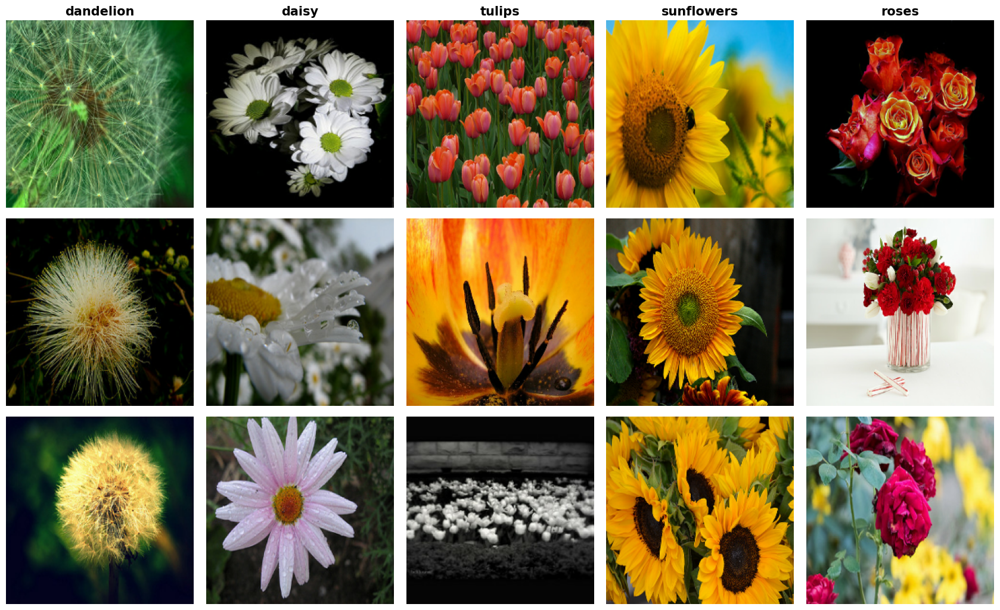

In [5]:
# ----------------------------- plot 1: sample images from all five classes -----------------------------
rng_s = np.random.RandomState(SEED)
fig, axs = plt.subplots(3, NUM_CLASSES, figsize=(3.4 * NUM_CLASSES, 10.5))
for c in range(NUM_CLASSES):
    ids = rng_s.choice(np.where(Y_TRAIN == c)[0], 3, replace=False)
    for r in range(3):
        axs[r, c].imshow(X_TRAIN[ids[r]])
        axs[r, c].axis('off')
    axs[0, c].set_title(CLASS_NAMES[c])
plt.tight_layout()
savefig('01_sample_images.png')

In [6]:
# ----------------------------- input pipeline -----------------------------
AUG = keras.Sequential([
    layers.RandomFlip('horizontal', seed=SEED),
    layers.RandomRotation(0.04, seed=SEED),
    layers.RandomZoom(0.1, seed=SEED),
    layers.RandomTranslation(0.1, 0.1, seed=SEED),
    layers.RandomContrast(0.1, seed=SEED),
], name='augmentation')

MEAN_BGR = tf.constant([103.939, 116.779, 123.68], dtype=tf.float32)

def preprocess(x):
    """RGB 0-255 -> ResNet50 (ImageNet 'caffe') preprocessing: RGB->BGR, mean subtraction."""
    x = tf.cast(x, tf.float32)
    return tf.reverse(x, axis=[-1]) - MEAN_BGR

def make_ds(X, y, train):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if train:
        ds = ds.shuffle(len(X), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH)
    if train:
        ds = ds.map(lambda a, b: (tf.clip_by_value(AUG(tf.cast(a, tf.float32), training=True), 0., 255.), b),
                    num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.map(lambda a, b: (preprocess(a), b), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(X_TRAIN, Y_TRAIN, True)
val_ds = make_ds(X_VAL, Y_VAL, False)
test_ds = make_ds(X_TEST, Y_TEST, False)
TEST_BATCHES = [(x.numpy(), y.numpy()) for x, y in test_ds]    # cached for inference timing / predictions
print('Test batches:', len(TEST_BATCHES), '| train steps/epoch:', math.ceil(len(X_TRAIN) / BATCH))

Test batches: 18 | train steps/epoch: 81


In [7]:
# ----------------------------- attention modules -----------------------------
class ChannelAttention(layers.Layer):
    """SE-style channel attention: GAP -> FC(C/r, ReLU) -> FC(C, sigmoid) -> rescale channels."""
    def __init__(self, ratio=16, **kw):
        super().__init__(**kw)
        self.ratio = ratio
    def build(self, s):
        C = int(s[-1]); h = max(C // self.ratio, 1)
        self.fc1 = layers.Dense(h, activation='relu')
        self.fc2 = layers.Dense(C, activation='sigmoid')
        self.fc1.build((None, C)); self.fc2.build((None, h))
        super().build(s)
    def chan_map(self, x):
        return self.fc2(self.fc1(tf.reduce_mean(x, axis=[1, 2])))
    def call(self, x):
        return x * self.chan_map(x)[:, None, None, :]
    def maps(self, x):
        return {'channel': self.chan_map(x)}


class SpatialAttention(layers.Layer):
    """Channel-wise mean and max -> concat -> kxk conv -> sigmoid -> rescale locations."""
    def __init__(self, ks=7, **kw):
        super().__init__(**kw)
        self.ks = ks
    def build(self, s):
        self.conv = layers.Conv2D(1, self.ks, padding='same', activation='sigmoid')
        self.conv.build((None, int(s[1]), int(s[2]), 2))
        super().build(s)
    def spat_map(self, x):
        avg = tf.reduce_mean(x, axis=-1, keepdims=True)
        mx = tf.reduce_max(x, axis=-1, keepdims=True)
        return self.conv(tf.concat([avg, mx], axis=-1))
    def call(self, x):
        return x * self.spat_map(x)
    def maps(self, x):
        return {'spatial': self.spat_map(x)[..., 0]}


class ChannelSpatial(layers.Layer):
    """order='cs': channel -> spatial ; order='sc': spatial -> channel."""
    def __init__(self, order='cs', ks=7, ratio=16, **kw):
        super().__init__(**kw)
        self.order, self.ks, self.ratio = order, ks, ratio
    def build(self, s):
        self.ca = ChannelAttention(self.ratio); self.sa = SpatialAttention(self.ks)
        self.ca.build(s); self.sa.build(s)
        super().build(s)
    def call(self, x):
        if self.order == 'cs':
            return self.sa(self.ca(x))
        return self.ca(self.sa(x))
    def maps(self, x):
        if self.order == 'cs':
            xc = self.ca(x)
            return {'channel': self.ca.chan_map(x), 'spatial': self.sa.spat_map(xc)[..., 0]}
        xs = self.sa(x)
        return {'spatial': self.sa.spat_map(x)[..., 0], 'channel': self.ca.chan_map(xs)}


class SelfAttention(layers.Layer):
    """Lightweight non-local self-attention: Q,K (C/8), V (C/2), softmax(QK^T/sqrt(d))V, residual with learnable gamma (init 0)."""
    def __init__(self, **kw):
        super().__init__(**kw)
    def build(self, s):
        self.H, self.W, self.C = int(s[1]), int(s[2]), int(s[3])
        self.d = max(self.C // 8, 1); self.dv = max(self.C // 2, 1)
        self.q = layers.Conv2D(self.d, 1, use_bias=False)
        self.k = layers.Conv2D(self.d, 1, use_bias=False)
        self.v = layers.Conv2D(self.dv, 1, use_bias=False)
        self.o = layers.Conv2D(self.C, 1, use_bias=False)
        for l in (self.q, self.k, self.v):
            l.build((None, self.H, self.W, self.C))
        self.o.build((None, self.H, self.W, self.dv))
        self.gamma = self.add_weight(name='gamma', shape=(1,), initializer='zeros', trainable=True)
        super().build(s)
    def attn_matrix(self, x):
        B = tf.shape(x)[0]; N = self.H * self.W
        q = tf.reshape(self.q(x), [B, N, self.d])
        k = tf.reshape(self.k(x), [B, N, self.d])
        return tf.nn.softmax(tf.matmul(q, k, transpose_b=True) / math.sqrt(self.d), axis=-1)
    def call(self, x):
        B = tf.shape(x)[0]; N = self.H * self.W
        A = self.attn_matrix(x)
        v = tf.reshape(self.v(x), [B, N, self.dv])
        y = tf.reshape(tf.matmul(A, v), [B, self.H, self.W, self.dv])
        return x + self.gamma * self.o(y)
    def maps(self, x):
        return {'attn_matrix': self.attn_matrix(x)}


class CombinedAttention(layers.Layer):
    """A5: channel -> spatial -> self-attention."""
    def __init__(self, ks=7, ratio=16, **kw):
        super().__init__(**kw)
        self.ks, self.ratio = ks, ratio
    def build(self, s):
        self.cs = ChannelSpatial('cs', self.ks, self.ratio); self.sat = SelfAttention()
        self.cs.build(s); self.sat.build(s)
        super().build(s)
    def call(self, x):
        return self.sat(self.cs(x))


class ECA(layers.Layer):
    """Efficient Channel Attention: GAP -> 1D conv (adaptive kernel) across channels -> sigmoid."""
    def __init__(self, **kw):
        super().__init__(**kw)
    def build(self, s):
        C = int(s[-1]); t = int(abs((math.log2(C) + 1) / 2))
        self.eks = t if t % 2 == 1 else t + 1
        self.conv = layers.Conv1D(1, self.eks, padding='same', use_bias=False)
        self.conv.build((None, C, 1))
        super().build(s)
    def chan_map(self, x):
        z = tf.reduce_mean(x, axis=[1, 2])[..., None]
        return tf.nn.sigmoid(self.conv(z))[..., 0]
    def call(self, x):
        return x * self.chan_map(x)[:, None, None, :]
    def maps(self, x):
        return {'channel': self.chan_map(x)}


class CBAM(layers.Layer):
    """CBAM: channel branch (shared MLP on avg- and max-pooled descriptors) then 7x7 spatial branch."""
    def __init__(self, ratio=16, ks=7, **kw):
        super().__init__(**kw)
        self.ratio, self.ks = ratio, ks
    def build(self, s):
        C = int(s[-1]); h = max(C // self.ratio, 1)
        self.fc1 = layers.Dense(h, activation='relu'); self.fc2 = layers.Dense(C)
        self.fc1.build((None, C)); self.fc2.build((None, h))
        self.sa = SpatialAttention(self.ks); self.sa.build(s)
        super().build(s)
    def chan_map(self, x):
        a = tf.reduce_mean(x, axis=[1, 2]); m = tf.reduce_max(x, axis=[1, 2])
        return tf.nn.sigmoid(self.fc2(self.fc1(a)) + self.fc2(self.fc1(m)))
    def call(self, x):
        return self.sa(x * self.chan_map(x)[:, None, None, :])
    def maps(self, x):
        xc = x * self.chan_map(x)[:, None, None, :]
        return {'channel': self.chan_map(x), 'spatial': self.sa.spat_map(xc)[..., 0]}


ATT_CLASSES = {'channel': ChannelAttention, 'spatial': SpatialAttention, 'cs': ChannelSpatial,
               'self': SelfAttention, 'combined': CombinedAttention, 'eca': ECA, 'cbam': CBAM}

def make_attention(spec, name):
    kind, kw = spec
    return ATT_CLASSES[kind](name=name, **kw)

STAGE_INFO = {1: (56, 56, 256), 2: (28, 28, 512), 3: (14, 14, 1024), 4: (7, 7, 2048)}   # P1..P4 (H, W, C)
STAGE_NAMES = {1: 'conv2_x', 2: 'conv3_x', 3: 'conv4_x', 4: 'conv5_x'}

In [8]:
# ----------------------------- sanity check: every module preserves tensor shape; parameter counts -----------------------------
SPECS = [('channel', dict(ratio=RATIO)), ('spatial', dict(ks=7)), ('cs', dict(order='cs', ks=7, ratio=RATIO)),
         ('cs', dict(order='sc', ks=7, ratio=RATIO)), ('self', dict()), ('combined', dict(ks=7, ratio=RATIO)),
         ('eca', dict()), ('cbam', dict(ratio=RATIO, ks=7))]
rows = []
for kind, kw in SPECS:
    for k, (H, W, C) in STAGE_INFO.items():
        if kind in ('self', 'combined') and k < 3:
            continue          # N x N attention matrix is impractical at high resolution (manual Sec. 12)
        layer = make_attention((kind, kw), 'tmp')
        x = tf.random.normal((2, H, W, C))
        y = layer(x)
        assert tuple(y.shape) == tuple(x.shape), (kind, k, y.shape, x.shape)
        rows.append({'Module': kind + ('-' + kw['order'] if 'order' in kw else ''), 'Position': f'P{k} ({STAGE_NAMES[k]})',
                     'Input (H,W,C)': (H, W, C), 'Output (H,W,C)': tuple(y.shape[1:]), 'Params': layer.count_params()})
df_mod = pd.DataFrame(rows)
df_mod.to_csv(TABLES / 'attention_module_params.csv', index=False)
display(df_mod)
print('All modules preserve the feature-tensor shape.')

,Module,Position,"Input (H,W,C)","Output (H,W,C)",Params
0,channel,P1 (conv2_x),"(56, 56, 256)","(56, 56, 256)",8464
1,channel,P2 (conv3_x),"(28, 28, 512)","(28, 28, 512)",33312
2,channel,P3 (conv4_x),"(14, 14, 1024)","(14, 14, 1024)",132160
3,channel,P4 (conv5_x),"(7, 7, 2048)","(7, 7, 2048)",526464
4,spatial,P1 (conv2_x),"(56, 56, 256)","(56, 56, 256)",99
5,spatial,P2 (conv3_x),"(28, 28, 512)","(28, 28, 512)",99
6,spatial,P3 (conv4_x),"(14, 14, 1024)","(14, 14, 1024)",99
7,spatial,P4 (conv5_x),"(7, 7, 2048)","(7, 7, 2048)",99
8,cs-cs,P1 (conv2_x),"(56, 56, 256)","(56, 56, 256)",8563
9,cs-cs,P2 (conv3_x),"(28, 28, 512)","(28, 28, 512)",33411


All modules preserve the feature-tensor shape.


In [9]:
# ----------------------------- model construction -----------------------------
STAGE_ENDS = ['conv2_block3_out', 'conv3_block4_out', 'conv4_block6_out', 'conv5_block3_out']

def build_model(pos_cfg, pretrained=True):
    """ResNet50 split into 4 stage-models (conv2_x..conv5_x) that share layers with the pretrained base;
    attention modules are inserted after the chosen stages: ... -> stage -> Attention -> next stage."""
    base = keras.applications.ResNet50(weights='imagenet' if pretrained else None,
                                       include_top=False, input_shape=(IMG, IMG, 3))
    inp = keras.Input((IMG, IMG, 3), name='image')
    x, prev = inp, base.input
    for k, end in enumerate(STAGE_ENDS, start=1):
        end_t = base.get_layer(end).output
        stage = keras.Model(prev, end_t, name=f'resnet_stage{k + 1}')   # P1 -> resnet_stage2 (conv2_x) ...
        x = stage(x)
        x = layers.Activation('linear', name=f'pre_P{k}')(x)           # tap: features entering position Pk (no parameters)
        if k in pos_cfg:
            x = make_attention(pos_cfg[k], name=f'att_P{k}')(x)
        prev = end_t
    x = layers.Activation('linear', name='final_features')(x)
    x = layers.GlobalAveragePooling2D(name='gap')(x)
    x = layers.Dropout(DROPOUT, name='drop')(x)
    out = layers.Dense(NUM_CLASSES, name='logits')(x)                    # logits; softmax is inside the loss
    return keras.Model(inp, out, name='resnet50_attention'), list(base.layers)

def set_trainable(base_layers, phase):
    """phase 1: whole pretrained backbone frozen. phase 2: conv5 stage unfrozen (BatchNorm kept frozen)."""
    for l in base_layers:
        l.trainable = False
    if phase == 2:
        for l in base_layers:
            if l.name.startswith('conv5_') and not isinstance(l, layers.BatchNormalization):
                l.trainable = True

def compile_model(model, lr):
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                  metrics=['accuracy'])

def count_trainable(model):
    return int(sum(int(np.prod(w.shape)) for w in model.trainable_weights))

def pos_label(pos_cfg):
    return '-' if not pos_cfg else '+'.join(f'P{k}' for k in sorted(pos_cfg))

# quick structural check on the baseline and a multi-position model (random weights, no download)
_m, _bl = build_model({2: ('cs', dict(order='cs', ks=7, ratio=RATIO)), 3: ('channel', dict(ratio=RATIO))}, pretrained=False)
for k in (2, 3):
    a = _m.get_layer(f'att_P{k}')
    print(f'att_P{k}: input {tuple(a.input.shape[1:])} -> output {tuple(a.output.shape[1:])}')
set_trainable(_bl, 1); print('trainable params, phase 1:', count_trainable(_m))
set_trainable(_bl, 2); print('trainable params, phase 2:', count_trainable(_m))
del _m, _bl
keras.backend.clear_session(); gc.collect()

att_P2: input (28, 28, 512) -> output (28, 28, 512)
att_P3: input (14, 14, 1024) -> output (14, 14, 1024)
trainable params, phase 1: 175816
trainable params, phase 2: 15129288


0

In [10]:
# ----------------------------- evaluation helpers -----------------------------
def predict_and_time(model, reps=3):
    """Test-set logits + inference time. Main number = ms/image with batch 32 (median of `reps` passes after a warm-up pass);
    also single-image latency (batch 1) averaged over 40 images."""
    fn = tf.function(lambda x: model(x, training=False),
                     input_signature=[tf.TensorSpec([None, IMG, IMG, 3], tf.float32)])
    for xb, _ in TEST_BATCHES:                       # warm-up (graph tracing, cudnn autotune)
        fn(xb).numpy()
    times = []
    for _ in range(reps):
        t0 = time.perf_counter()
        outs = [fn(xb).numpy() for xb, _ in TEST_BATCHES]
        times.append(time.perf_counter() - t0)
    logits = np.concatenate(outs)
    ms_bs32 = 1000.0 * float(np.median(times)) / len(logits)
    single = TEST_BATCHES[0][0][:min(40, len(TEST_BATCHES[0][0]))]
    for i in range(3):
        fn(single[i:i + 1]).numpy()
    t0 = time.perf_counter()
    for i in range(len(single)):
        fn(single[i:i + 1]).numpy()
    ms_bs1 = 1000.0 * (time.perf_counter() - t0) / len(single)
    return logits, ms_bs32, ms_bs1

def classification_metrics(y_true, logits):
    pred = logits.argmax(1)
    p, r, f, _ = precision_recall_fscore_support(y_true, pred, average='macro', zero_division=0)
    pc, rc, fc, sc = precision_recall_fscore_support(y_true, pred, labels=list(range(NUM_CLASSES)), average=None, zero_division=0)
    loss = float(np.mean(keras.losses.sparse_categorical_crossentropy(y_true, logits, from_logits=True)))
    return {'test_acc': float(accuracy_score(y_true, pred)), 'test_loss': loss,
            'precision': float(p), 'recall': float(r), 'f1': float(f),
            'per_class': {CLASS_NAMES[i]: {'precision': float(pc[i]), 'recall': float(rc[i]), 'f1': float(fc[i]), 'support': int(sc[i])}
                          for i in range(NUM_CLASSES)},
            'confusion': confusion_matrix(y_true, pred, labels=list(range(NUM_CLASSES))).tolist()}

# ----------------------------- experiment definitions -----------------------------
def CS(order='cs', ks=7):
    return ('cs', dict(order=order, ks=ks, ratio=RATIO))

EXPERIMENTS = {
    # Experiment 1 - attention type @P3
    'A0': dict(name='Baseline ResNet50', pos={}),
    'A1': dict(name='Channel (SE)', pos={3: ('channel', dict(ratio=RATIO))}),
    'A2': dict(name='Spatial', pos={3: ('spatial', dict(ks=7))}),
    'A3': dict(name='Channel+Spatial', pos={3: CS('cs', 7)}),
    'A4': dict(name='Self-Attention', pos={3: ('self', dict())}),
    'A5': dict(name='Combined (C+S+SA)', pos={3: ('combined', dict(ks=7, ratio=RATIO))}),
    # Experiment 2 - position (Channel->Spatial); B3 is A3
    'B1': dict(name='Channel+Spatial', pos={1: CS()}),
    'B2': dict(name='Channel+Spatial', pos={2: CS()}),
    'B4': dict(name='Channel+Spatial', pos={4: CS()}),
    # Experiment 3 - multiple positions (P3 only = A3, P4 only = B4)
    'M34': dict(name='Channel+Spatial', pos={3: CS(), 4: CS()}),
    'M234': dict(name='Channel+Spatial', pos={2: CS(), 3: CS(), 4: CS()}),
    # Experiment 4 - order
    'O_SC': dict(name='Spatial->Channel', pos={3: CS('sc', 7)}),
    # Experiment 5 - spatial kernel (7x7 is A3)
    'K3': dict(name='Channel+Spatial k=3', pos={3: CS('cs', 3)}),
    'K5': dict(name='Channel+Spatial k=5', pos={3: CS('cs', 5)}),
    # Additional mechanisms
    'ECA': dict(name='ECA', pos={3: ('eca', dict())}),
    'CBAM': dict(name='CBAM', pos={3: ('cbam', dict(ratio=RATIO, ks=7))}),
}
GROUPS = {
    'Exp 1 - attention type @P3': ['A0', 'A1', 'A2', 'A3', 'A4', 'A5'],
    'Exp 2 - position (C->S)': ['B2', 'B4', 'B1'],
    'Exp 3 - multiple positions': ['M34', 'M234'],
    'Exp 4 - order and Exp 5 - kernel size': ['O_SC', 'K3', 'K5'],
    'Additional mechanisms': ['ECA', 'CBAM'],
}
print('Total training runs:', len(EXPERIMENTS))

def run_experiment(key, force=False):
    cfg = EXPERIMENTS[key]
    if (CKPT / f'{key}.json').exists() and not force:
        print(f'[skip] {key}: finished checkpoint found'); return
    n_done = len(list(CKPT.glob('*.json')))
    print('=' * 100)
    print(f'RUN {key} ({n_done + 1}/{len(EXPERIMENTS)}): {cfg["name"]} | positions: {pos_label(cfg["pos"])}')
    keras.backend.clear_session(); gc.collect()
    keras.utils.set_random_seed(SEED)
    model, base_layers = build_model(cfg['pos'], PRETRAINED)

    t0 = time.time()
    set_trainable(base_layers, 1); compile_model(model, LR_HEAD)
    n_tr1 = count_trainable(model)
    print(f'phase 1 (backbone frozen) trainable params: {n_tr1:,}')
    h1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FROZEN, verbose=2)
    set_trainable(base_layers, 2); compile_model(model, LR_FINETUNE)
    n_tr2 = count_trainable(model)
    print(f'phase 2 (conv5 unfrozen) trainable params: {n_tr2:,}')
    h2 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FINETUNE, verbose=2)
    train_time = time.time() - t0

    # metrics come from the History objects, never from tracker .result()
    hist = {k: [float(v) for v in (h1.history[k] + h2.history[k])] for k in ('loss', 'accuracy', 'val_loss', 'val_accuracy')}
    logits, ms32, ms1 = predict_and_time(model)
    m = classification_metrics(Y_TEST, logits)

    shapes = {}
    for k in cfg['pos']:
        a = model.get_layer(f'att_P{k}')
        shapes[f'P{k}'] = {'location': f'after {STAGE_NAMES[k]}', 'input': list(a.input.shape[1:]), 'output': list(a.output.shape[1:])}
    att_params = int(sum(model.get_layer(f'att_P{k}').count_params() for k in cfg['pos']))
    extra = {}
    for k in cfg['pos']:
        a = model.get_layer(f'att_P{k}')
        if isinstance(a, SelfAttention):
            extra[f'gamma_P{k}'] = float(a.gamma.numpy()[0])
        if isinstance(a, CombinedAttention):
            extra[f'gamma_P{k}'] = float(a.sat.gamma.numpy()[0])

    metrics = {'key': key, 'name': cfg['name'], 'pos_label': pos_label(cfg['pos']), 'att_shapes': shapes, 'extra': extra,
               'train_acc': hist['accuracy'][-1], 'val_acc': hist['val_accuracy'][-1],
               'train_loss': hist['loss'][-1], 'val_loss': hist['val_loss'][-1],
               'params_total': int(model.count_params()), 'params_trainable': n_tr2, 'params_trainable_phase1': n_tr1,
               'params_attention': att_params, 'infer_ms_bs32': ms32, 'infer_ms_bs1': ms1, 'train_time_s': train_time,
               'epochs': [EPOCHS_FROZEN, EPOCHS_FINETUNE], 'history': hist, **m}
    save_checkpoint(key, model, metrics, logits)
    print(f'>> {key}: test acc {m["test_acc"]*100:.2f}% | macro-F1 {m["f1"]*100:.2f}% | params {metrics["params_total"]:,} '
          f'| {ms32:.2f} ms/img | run time {train_time/60:.1f} min')
    del model, base_layers
    keras.backend.clear_session(); gc.collect()

Total training runs: 16


In [11]:
# ===== Experiment 1: attention type at P3 (A0-A5). ~6 runs, ~40-60 min on GPU =====
for key in GROUPS['Exp 1 - attention type @P3']:
    run_experiment(key)

RUN A0 (1/16): Baseline ResNet50 | positions: -
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
phase 1 (backbone frozen) trainable params: 10,245
Epoch 1/10


I0000 00:00:1790934089.207942      70 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


81/81 - 47s - 576ms/step - accuracy: 0.7049 - loss: 0.8115 - val_accuracy: 0.8818 - val_loss: 0.3722
Epoch 2/10
81/81 - 20s - 246ms/step - accuracy: 0.8361 - loss: 0.4228 - val_accuracy: 0.8873 - val_loss: 0.3268
Epoch 3/10
81/81 - 20s - 248ms/step - accuracy: 0.8836 - loss: 0.3203 - val_accuracy: 0.9091 - val_loss: 0.2767
Epoch 4/10
81/81 - 20s - 251ms/step - accuracy: 0.8918 - loss: 0.2958 - val_accuracy: 0.9073 - val_loss: 0.2701
Epoch 5/10
81/81 - 20s - 248ms/step - accuracy: 0.9050 - loss: 0.2574 - val_accuracy: 0.9109 - val_loss: 0.2577
Epoch 6/10
81/81 - 20s - 249ms/step - accuracy: 0.9175 - loss: 0.2400 - val_accuracy: 0.9073 - val_loss: 0.2474
Epoch 7/10
81/81 - 20s - 252ms/step - accuracy: 0.9198 - loss: 0.2287 - val_accuracy: 0.9036 - val_loss: 0.2418
Epoch 8/10
81/81 - 20s - 244ms/step - accuracy: 0.9315 - loss: 0.1983 - val_accuracy: 0.9145 - val_loss: 0.2232
Epoch 9/10
81/81 - 20s - 249ms/step - accuracy: 0.9264 - loss: 0.2019 - val_accuracy: 0.8945 - val_loss: 0.2836
Epo

In [12]:
# ===== Experiment 2: attention position, Channel->Spatial (B2, B4, B1; B3 = A3). 3 runs. B1/B2 are slower (backprop through more frozen stages) =====
for key in GROUPS['Exp 2 - position (C->S)']:
    run_experiment(key)

RUN B2 (7/16): Channel+Spatial | positions: P2
phase 1 (backbone frozen) trainable params: 43,656
Epoch 1/10
81/81 - 49s - 609ms/step - accuracy: 0.3920 - loss: 1.4796 - val_accuracy: 0.7145 - val_loss: 0.7407
Epoch 2/10
81/81 - 22s - 270ms/step - accuracy: 0.8069 - loss: 0.5143 - val_accuracy: 0.8509 - val_loss: 0.4145
Epoch 3/10
81/81 - 21s - 263ms/step - accuracy: 0.8692 - loss: 0.3700 - val_accuracy: 0.8873 - val_loss: 0.3331
Epoch 4/10
81/81 - 21s - 262ms/step - accuracy: 0.8848 - loss: 0.3085 - val_accuracy: 0.8982 - val_loss: 0.3031
Epoch 5/10
81/81 - 21s - 264ms/step - accuracy: 0.9035 - loss: 0.2660 - val_accuracy: 0.8927 - val_loss: 0.2872
Epoch 6/10
81/81 - 21s - 265ms/step - accuracy: 0.9112 - loss: 0.2471 - val_accuracy: 0.9091 - val_loss: 0.2716
Epoch 7/10
81/81 - 21s - 264ms/step - accuracy: 0.9233 - loss: 0.2032 - val_accuracy: 0.8873 - val_loss: 0.3234
Epoch 8/10
81/81 - 21s - 264ms/step - accuracy: 0.9327 - loss: 0.1888 - val_accuracy: 0.8982 - val_loss: 0.3048
Epoch 

In [13]:
# ===== Experiment 3: multiple positions (P3+P4, P2+P3+P4). 2 runs =====
for key in GROUPS['Exp 3 - multiple positions']:
    run_experiment(key)

RUN M34 (10/16): Channel+Spatial | positions: P3+P4
phase 1 (backbone frozen) trainable params: 669,067
Epoch 1/10
81/81 - 50s - 621ms/step - accuracy: 0.3009 - loss: 1.5100 - val_accuracy: 0.7436 - val_loss: 0.8489
Epoch 2/10
81/81 - 21s - 260ms/step - accuracy: 0.8135 - loss: 0.5083 - val_accuracy: 0.8709 - val_loss: 0.3393
Epoch 3/10
81/81 - 21s - 256ms/step - accuracy: 0.8859 - loss: 0.3113 - val_accuracy: 0.9000 - val_loss: 0.2660
Epoch 4/10
81/81 - 21s - 257ms/step - accuracy: 0.9225 - loss: 0.2216 - val_accuracy: 0.8891 - val_loss: 0.3116
Epoch 5/10
81/81 - 21s - 253ms/step - accuracy: 0.9389 - loss: 0.1852 - val_accuracy: 0.8982 - val_loss: 0.3299
Epoch 6/10
81/81 - 21s - 259ms/step - accuracy: 0.9510 - loss: 0.1460 - val_accuracy: 0.9182 - val_loss: 0.2408
Epoch 7/10
81/81 - 21s - 260ms/step - accuracy: 0.9607 - loss: 0.1114 - val_accuracy: 0.9127 - val_loss: 0.3162
Epoch 8/10
81/81 - 21s - 254ms/step - accuracy: 0.9685 - loss: 0.0897 - val_accuracy: 0.9255 - val_loss: 0.2833


In [14]:
# ===== Experiment 4 (order: Spatial->Channel @P3) and Experiment 5 (kernel 3 and 5; 7 = A3). 3 runs =====
for key in GROUPS['Exp 4 - order and Exp 5 - kernel size']:
    run_experiment(key)

RUN O_SC (12/16): Spatial->Channel | positions: P3
phase 1 (backbone frozen) trainable params: 142,504
Epoch 1/10
81/81 - 45s - 557ms/step - accuracy: 0.3227 - loss: 1.4878 - val_accuracy: 0.7727 - val_loss: 0.6617
Epoch 2/10
81/81 - 21s - 260ms/step - accuracy: 0.8225 - loss: 0.4682 - val_accuracy: 0.8673 - val_loss: 0.3830
Epoch 3/10
81/81 - 21s - 258ms/step - accuracy: 0.8836 - loss: 0.3252 - val_accuracy: 0.8927 - val_loss: 0.2934
Epoch 4/10
81/81 - 21s - 255ms/step - accuracy: 0.8941 - loss: 0.2926 - val_accuracy: 0.9036 - val_loss: 0.2801
Epoch 5/10
81/81 - 21s - 258ms/step - accuracy: 0.9089 - loss: 0.2486 - val_accuracy: 0.9073 - val_loss: 0.2555
Epoch 6/10
81/81 - 21s - 253ms/step - accuracy: 0.9210 - loss: 0.2230 - val_accuracy: 0.9164 - val_loss: 0.2418
Epoch 7/10
81/81 - 21s - 256ms/step - accuracy: 0.9323 - loss: 0.1863 - val_accuracy: 0.9055 - val_loss: 0.2526
Epoch 8/10
81/81 - 21s - 259ms/step - accuracy: 0.9432 - loss: 0.1779 - val_accuracy: 0.9000 - val_loss: 0.2627
E

In [15]:
# ===== Additional mechanisms: ECA and CBAM at P3 (SE = A1, Self-attention = A4). 2 runs =====
for key in GROUPS['Additional mechanisms']:
    run_experiment(key)

RUN ECA (15/16): ECA | positions: P3
phase 1 (backbone frozen) trainable params: 10,250
Epoch 1/10
81/81 - 46s - 567ms/step - accuracy: 0.6450 - loss: 0.9274 - val_accuracy: 0.8545 - val_loss: 0.4277
Epoch 2/10
81/81 - 21s - 260ms/step - accuracy: 0.8404 - loss: 0.4452 - val_accuracy: 0.8891 - val_loss: 0.3344
Epoch 3/10
81/81 - 21s - 254ms/step - accuracy: 0.8743 - loss: 0.3590 - val_accuracy: 0.8818 - val_loss: 0.3112
Epoch 4/10
81/81 - 21s - 255ms/step - accuracy: 0.8976 - loss: 0.2960 - val_accuracy: 0.8945 - val_loss: 0.2901
Epoch 5/10
81/81 - 21s - 260ms/step - accuracy: 0.9101 - loss: 0.2556 - val_accuracy: 0.8909 - val_loss: 0.2809
Epoch 6/10
81/81 - 21s - 255ms/step - accuracy: 0.9237 - loss: 0.2349 - val_accuracy: 0.8873 - val_loss: 0.2912
Epoch 7/10
81/81 - 21s - 258ms/step - accuracy: 0.9284 - loss: 0.2176 - val_accuracy: 0.9000 - val_loss: 0.2839
Epoch 8/10
81/81 - 21s - 260ms/step - accuracy: 0.9288 - loss: 0.2055 - val_accuracy: 0.9000 - val_loss: 0.2697
Epoch 9/10
81/81

In [16]:
# ----------------------------- load all finished runs -----------------------------
missing = [k for k in EXPERIMENTS if not (CKPT / f'{k}.json').exists()]
assert not missing, f'These runs are not finished: {missing}'
RESULTS = {k: json.load(open(CKPT / f'{k}.json')) for k in EXPERIMENTS}
LOGITS = {k: np.load(CKPT / f'{k}_logits.npy') for k in EXPERIMENTS}
BASE_PARAMS = RESULTS['A0']['params_total']

def make_table(keys, labels=None):
    rows = []
    for i, k in enumerate(keys):
        r = RESULTS[k]
        rows.append({'Run': k, 'Model': labels[i] if labels else r['name'], 'Position': r['pos_label'],
                     'Train Acc (%)': 100 * r['train_acc'], 'Val Acc (%)': 100 * r['val_acc'], 'Test Acc (%)': 100 * r['test_acc'],
                     'Precision (%)': 100 * r['precision'], 'Recall (%)': 100 * r['recall'], 'Macro F1 (%)': 100 * r['f1'],
                     'Params total': r['params_total'], 'Params trainable': r['params_trainable'],
                     'Params added': r['params_total'] - BASE_PARAMS,
                     'Infer ms/img (bs32)': r['infer_ms_bs32'], 'Infer ms/img (bs1)': r['infer_ms_bs1'],
                     'Train time (min)': r['train_time_s'] / 60})
    return pd.DataFrame(rows).round(3)

TABLE_DEFS = {
    'table_attention_type': (['A0', 'A1', 'A2', 'A3', 'A4', 'A5'],
        ['A0 Baseline', 'A1 Channel', 'A2 Spatial', 'A3 Channel+Spatial', 'A4 Self-Attention', 'A5 Combined']),
    'table_position': (['A0', 'B1', 'B2', 'A3', 'B4'],
        ['Baseline', 'B1 C+S after conv2_x', 'B2 C+S after conv3_x', 'B3 C+S after conv4_x', 'B4 C+S after conv5_x']),
    'table_multi_position': (['A0', 'A3', 'B4', 'M34', 'M234'],
        ['Baseline', 'P3 only', 'P4 only', 'P3+P4', 'P2+P3+P4']),
    'table_order': (['A3', 'O_SC'], ['Channel->Spatial', 'Spatial->Channel']),
    'table_kernel': (['K3', 'K5', 'A3'], ['3x3', '5x5', '7x7']),
    'table_mechanism_comparison': (['A0', 'A1', 'A2', 'ECA', 'CBAM', 'A4', 'A3'],
        ['No Attention', 'Channel / SE', 'Spatial', 'ECA', 'CBAM', 'Self-Attention', 'Channel+Spatial']),
    'table_main_result': (['A0', 'A1', 'A2', 'B2', 'A3', 'B4', 'A4', 'ECA', 'CBAM'],
        ['Baseline', 'Channel Attention', 'Spatial Attention', 'Channel+Spatial (P2)', 'Channel+Spatial (P3)',
         'Channel+Spatial (P4)', 'Self-Attention', 'Additional-1: ECA', 'Additional-2: CBAM']),
}
TABLES_DF = {}
for name, (keys, labels) in TABLE_DEFS.items():
    TABLES_DF[name] = make_table(keys, labels)
    TABLES_DF[name].to_csv(TABLES / f'{name}.csv', index=False)
    print('\n###', name)
    display(TABLES_DF[name])

df_all = make_table(list(EXPERIMENTS))
df_all.to_csv(WORK / 'results_summary.csv', index=False)
pc = pd.DataFrame({k: {c: 100 * RESULTS[k]['per_class'][c]['f1'] for c in CLASS_NAMES} for k in EXPERIMENTS}).T.round(2)
pc.index.name = 'Run'
pc.to_csv(TABLES / 'per_class_f1.csv')
print('\n### per-class F1 (%)'); display(pc)

dims = [{'Run': k, 'Position': p, 'Location': v['location'], 'Input (H,W,C)': tuple(v['input']), 'Output (H,W,C)': tuple(v['output'])}
        for k, r in RESULTS.items() for p, v in r['att_shapes'].items()]
pd.DataFrame(dims).to_csv(TABLES / 'attention_io_dimensions.csv', index=False)
print('\n### attention input/output dimensions'); display(pd.DataFrame(dims))
print('\nSelf-attention gate gamma after training (0 = module is an identity):',
      {k: r['extra'] for k, r in RESULTS.items() if r['extra']})
print('Test-set size:', len(Y_TEST), '| one image =', round(100 / len(Y_TEST), 3), 'accuracy points')


### table_attention_type


,Run,Model,Position,Train Acc (%),Val Acc (%),Test Acc (%),Precision (%),Recall (%),Macro F1 (%),Params total,Params trainable,Params added,Infer ms/img (bs32),Infer ms/img (bs1),Train time (min)
0,A0,A0 Baseline,-,99.416,93.273,92.740,93.083,92.471,92.504,23597957,14963717,0,4.545,11.059,7.812
1,A1,A1 Channel,P3,99.066,93.455,92.559,92.807,92.438,92.443,23730117,15095877,132160,4.473,11.173,8.563
2,A2,A2 Spatial,P3,98.910,93.818,91.652,91.871,91.251,91.506,23598056,14963816,99,4.503,11.778,7.909
3,A3,A3 Channel+Spatial,P3,98.949,91.818,91.107,91.975,90.869,90.907,23730216,15095976,132259,4.626,12.188,8.029
4,A4,A4 Self-Attention,P3,98.365,93.273,91.833,91.941,91.533,91.684,24908678,16274438,1310721,4.731,12.312,8.125
5,A5,A5 Combined,P3,98.404,93.818,92.196,92.573,91.832,92.133,25040937,16406697,1442980,4.759,12.160,8.181



### table_position


,Run,Model,Position,Train Acc (%),Val Acc (%),Test Acc (%),Precision (%),Recall (%),Macro F1 (%),Params total,Params trainable,Params added,Infer ms/img (bs32),Infer ms/img (bs1),Train time (min)
0,A0,Baseline,-,99.416,93.273,92.740,93.083,92.471,92.504,23597957,14963717,0,4.545,11.059,7.812
1,B1,B1 C+S after conv2_x,P1,98.054,92.727,90.926,91.262,90.386,90.714,23606520,14972280,8563,4.689,12.352,8.274
2,B2,B2 C+S after conv3_x,P2,98.170,92.545,91.833,92.325,91.127,91.531,23631368,14997128,33411,4.607,11.499,8.190
3,A3,B3 C+S after conv4_x,P3,98.949,91.818,91.107,91.975,90.869,90.907,23730216,15095976,132259,4.626,12.188,8.029
4,B4,B4 C+S after conv5_x,P4,98.482,92.909,91.833,92.296,91.639,91.804,24124520,15490280,526563,4.634,12.475,7.885



### table_multi_position


...


### per-class F1 (%)


,dandelion,daisy,tulips,sunflowers,roses
Run,,,,,
A0,96.38,91.53,91.30,95.69,87.62
A1,95.65,93.41,89.08,97.12,86.96
A2,94.93,94.51,87.70,95.73,84.66
A3,96.06,91.53,88.50,93.00,85.45
A4,96.24,92.97,87.65,95.69,85.86
A5,93.24,93.41,90.00,96.19,87.83
B1,93.82,89.13,89.33,94.06,87.23
B2,94.96,92.31,88.98,97.61,83.80
B4,95.02,95.08,87.50,94.93,86.49



### attention input/output dimensions


,Run,Position,Location,"Input (H,W,C)","Output (H,W,C)"
0,A1,P3,after conv4_x,"(14, 14, 1024)","(14, 14, 1024)"
1,A2,P3,after conv4_x,"(14, 14, 1024)","(14, 14, 1024)"
2,A3,P3,after conv4_x,"(14, 14, 1024)","(14, 14, 1024)"
3,A4,P3,after conv4_x,"(14, 14, 1024)","(14, 14, 1024)"
4,A5,P3,after conv4_x,"(14, 14, 1024)","(14, 14, 1024)"
5,B1,P1,after conv2_x,"(56, 56, 256)","(56, 56, 256)"
6,B2,P2,after conv3_x,"(28, 28, 512)","(28, 28, 512)"
7,B4,P4,after conv5_x,"(7, 7, 2048)","(7, 7, 2048)"
8,M34,P3,after conv4_x,"(14, 14, 1024)","(14, 14, 1024)"
9,M34,P4,after conv5_x,"(7, 7, 2048)","(7, 7, 2048)"



Self-attention gate gamma after training (0 = module is an identity): {'A4': {'gamma_P3': -0.023534629493951797}, 'A5': {'gamma_P3': -0.01977030374109745}}
Test-set size: 551 | one image = 0.181 accuracy points


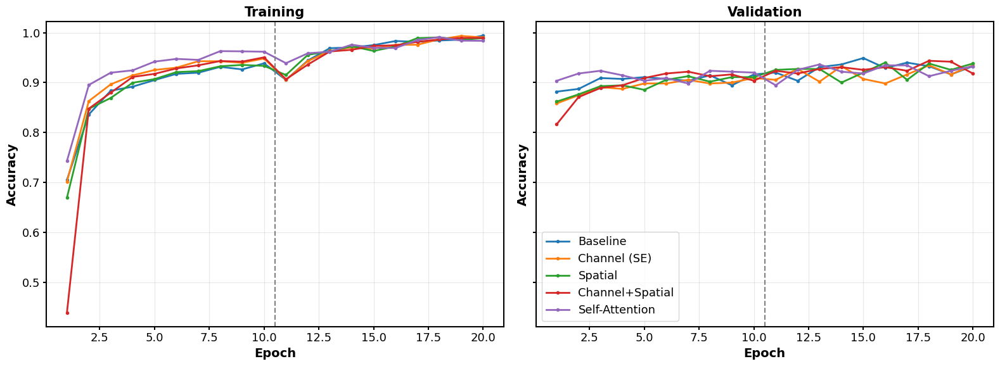

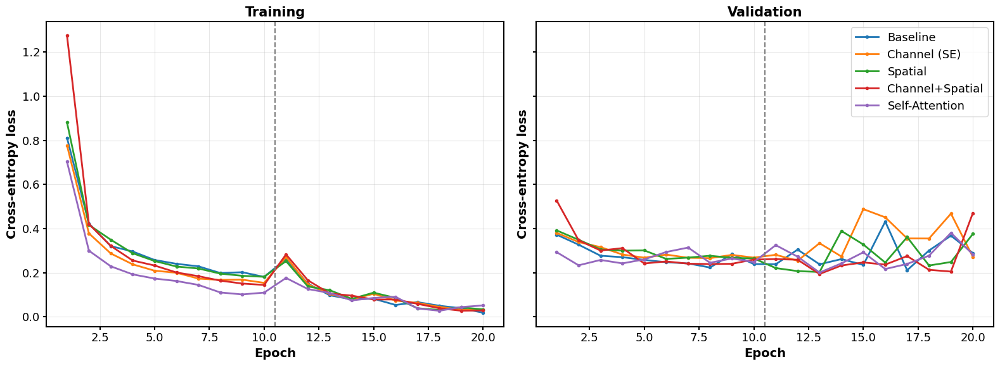

In [17]:
# ----------------------------- plots 2-3: training / validation curves -----------------------------
CURVE_KEYS = ['A0', 'A1', 'A2', 'A3', 'A4']
CURVE_LABELS = {'A0': 'Baseline', 'A1': 'Channel (SE)', 'A2': 'Spatial', 'A3': 'Channel+Spatial', 'A4': 'Self-Attention'}

def plot_curves(metric, ylabel, fname):
    fig, axs = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
    for k in CURVE_KEYS:
        h = RESULTS[k]['history']
        ep = np.arange(1, len(h[metric]) + 1)
        axs[0].plot(ep, h[metric], marker='o', ms=3, lw=2, label=CURVE_LABELS[k])
        axs[1].plot(ep, h['val_' + metric], marker='o', ms=3, lw=2, label=CURVE_LABELS[k])
    for ax, t in zip(axs, ('Training', 'Validation')):
        ax.axvline(EPOCHS_FROZEN + 0.5, ls='--', c='gray', lw=1.5)
        ax.set_xlabel('Epoch'); ax.set_ylabel(ylabel); ax.set_title(t); ax.grid(alpha=0.3)
    axs[1].legend()
    plt.tight_layout()
    savefig(fname)

plot_curves('accuracy', 'Accuracy', '02_accuracy_curves.png')
plot_curves('loss', 'Cross-entropy loss', '03_loss_curves.png')

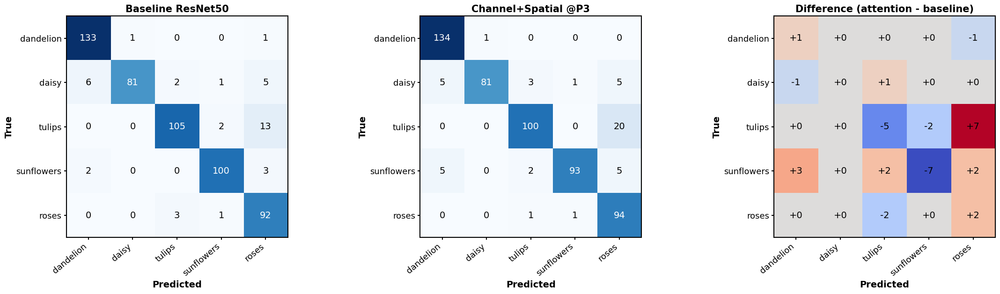

Per-class F1 (%): baseline vs Channel+Spatial @P3


,baseline,C+S @P3
dandelion,96.38,96.06
daisy,91.53,91.53
tulips,91.30,88.50
sunflowers,95.69,93.00
roses,87.62,85.45


In [18]:
# ----------------------------- plots 4-5: confusion matrices (baseline vs Channel+Spatial @P3) -----------------------------
def cm_of(k):
    return np.array(RESULTS[k]['confusion'])

cm0, cm3 = cm_of('A0'), cm_of('A3')
fig, axs = plt.subplots(1, 3, figsize=(23, 6.5))
for ax, cm, t in ((axs[0], cm0, 'Baseline ResNet50'), (axs[1], cm3, 'Channel+Spatial @P3')):
    im = ax.imshow(cm, cmap='Blues')
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(j, i, int(cm[i, j]), ha='center', va='center', fontsize=14,
                    color='white' if cm[i, j] > cm.max() * 0.6 else 'black')
    ax.set_title(t); ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    ax.set_xticks(range(NUM_CLASSES)); ax.set_yticks(range(NUM_CLASSES))
    ax.set_xticklabels(CLASS_NAMES, rotation=40, ha='right'); ax.set_yticklabels(CLASS_NAMES)
d = cm3 - cm0
lim = max(1, np.abs(d).max())
im = axs[2].imshow(d, cmap='coolwarm', vmin=-lim, vmax=lim)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        axs[2].text(j, i, f'{int(d[i, j]):+d}', ha='center', va='center', fontsize=14)
axs[2].set_title('Difference (attention - baseline)'); axs[2].set_xlabel('Predicted'); axs[2].set_ylabel('True')
axs[2].set_xticks(range(NUM_CLASSES)); axs[2].set_yticks(range(NUM_CLASSES))
axs[2].set_xticklabels(CLASS_NAMES, rotation=40, ha='right'); axs[2].set_yticklabels(CLASS_NAMES)
plt.tight_layout()
savefig('04_confusion_matrices.png')
print('Per-class F1 (%): baseline vs Channel+Spatial @P3')
display(pd.DataFrame({'baseline': {c: 100 * RESULTS['A0']['per_class'][c]['f1'] for c in CLASS_NAMES},
                      'C+S @P3': {c: 100 * RESULTS['A3']['per_class'][c]['f1'] for c in CLASS_NAMES}}).round(2))

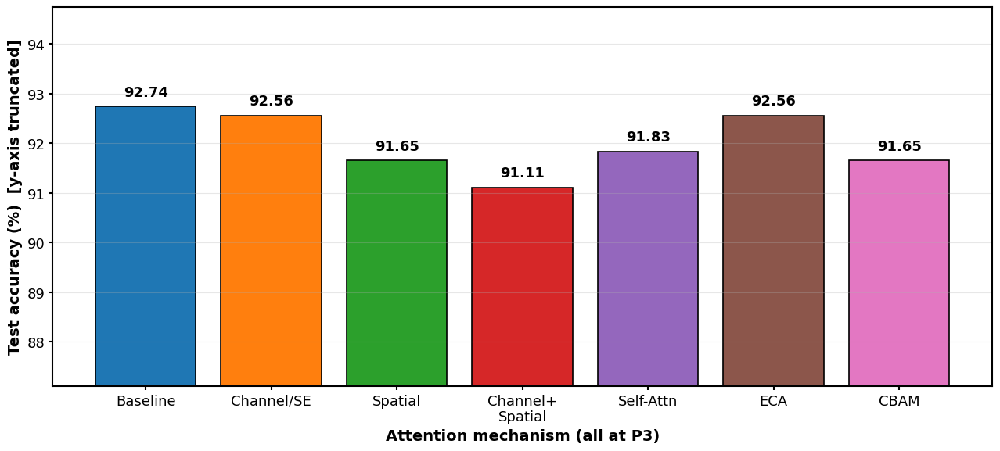

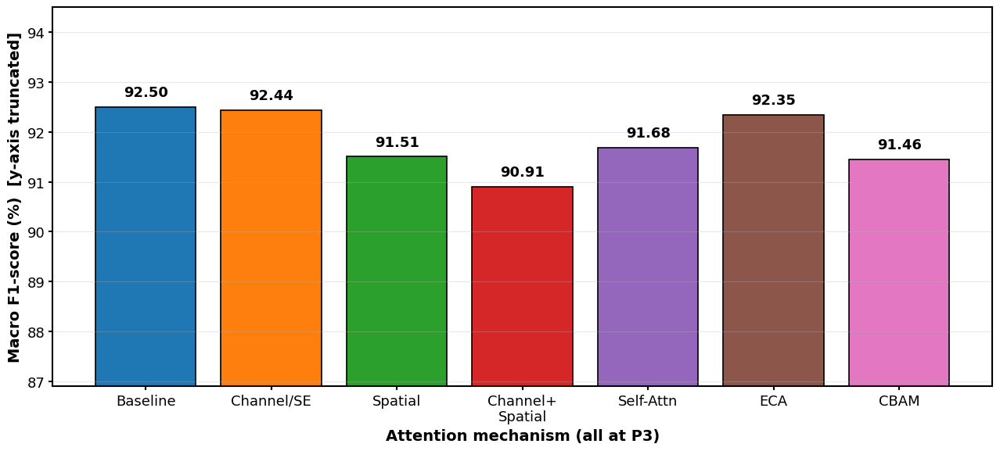

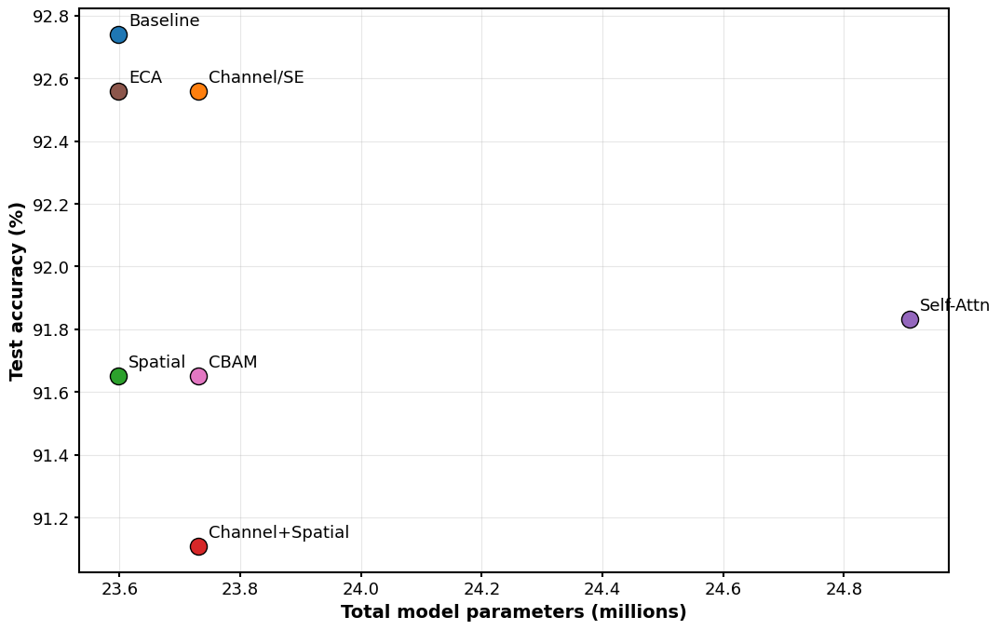

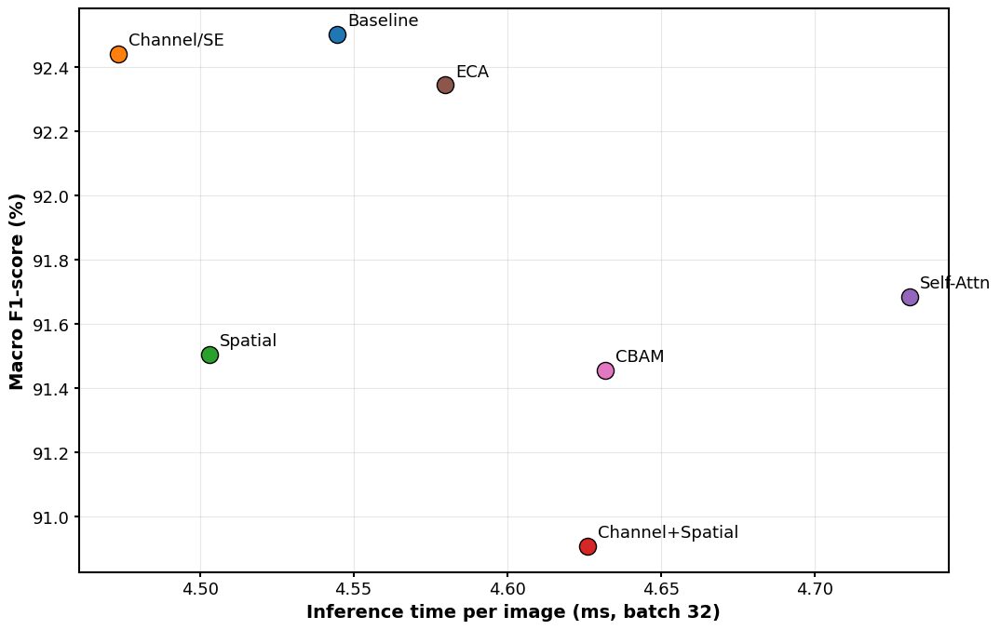

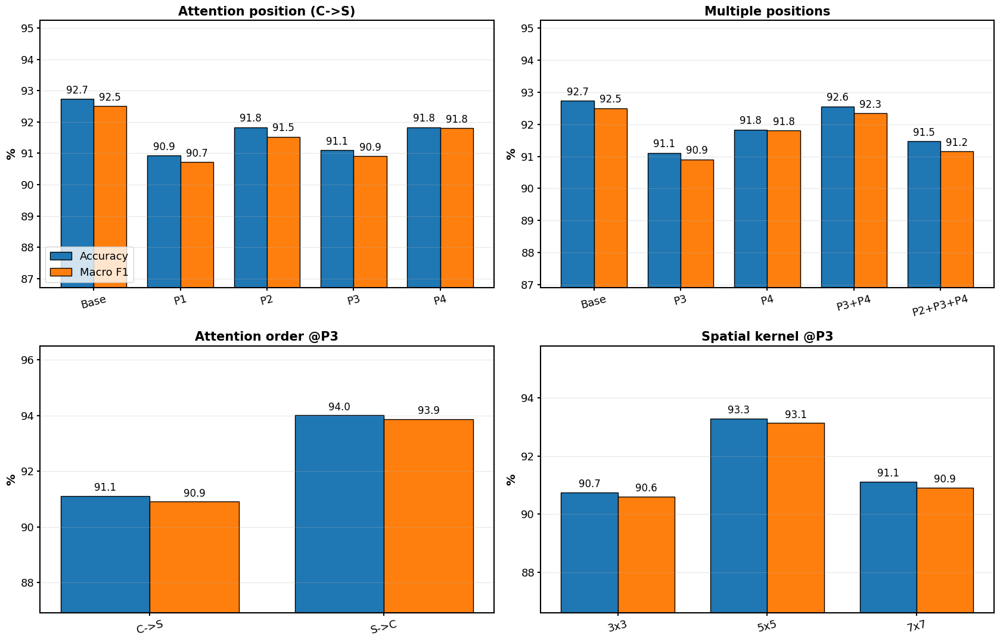

In [19]:
# ----------------------------- plots 5-8: comparison across mechanisms -----------------------------
MECH = [('A0', 'Baseline'), ('A1', 'Channel/SE'), ('A2', 'Spatial'), ('A3', 'Channel+\nSpatial'),
        ('A4', 'Self-Attn'), ('ECA', 'ECA'), ('CBAM', 'CBAM')]

def bar_metric(metric, ylabel, fname):
    vals = [100 * RESULTS[k][metric] for k, _ in MECH]
    fig, ax = plt.subplots(figsize=(13, 6))
    bars = ax.bar([l for _, l in MECH], vals, color=plt.cm.tab10(np.arange(len(MECH))), edgecolor='black', lw=1.2)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.15, f'{v:.2f}', ha='center', va='bottom', fontsize=13, fontweight='bold')
    ax.set_ylim(max(0, min(vals) - 4), min(100.5, max(vals) + 2))
    ax.set_ylabel(ylabel + ' (%)  [y-axis truncated]'); ax.set_xlabel('Attention mechanism (all at P3)')
    ax.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    savefig(fname)

bar_metric('test_acc', 'Test accuracy', '05_bar_accuracy.png')
bar_metric('f1', 'Macro F1-score', '06_bar_macro_f1.png')

def scatter(xkey, xlabel, ykey, ylabel, fname, xscale=1.0):
    fig, ax = plt.subplots(figsize=(11, 7))
    for i, (k, l) in enumerate(MECH):
        x = RESULTS[k][xkey] / xscale; y = 100 * RESULTS[k][ykey]
        ax.scatter(x, y, s=170, color=plt.cm.tab10(i), edgecolor='black', zorder=3)
        ax.annotate(l.replace('\n', ''), (x, y), textcoords='offset points', xytext=(8, 7), fontsize=13)
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.grid(alpha=0.3)
    plt.tight_layout()
    savefig(fname)

scatter('params_total', 'Total model parameters (millions)', 'test_acc', 'Test accuracy (%)', '07_scatter_accuracy_vs_params.png', 1e6)
scatter('infer_ms_bs32', 'Inference time per image (ms, batch 32)', 'f1', 'Macro F1-score (%)', '08_scatter_f1_vs_inference_time.png')

# ablation summary (position / multi-position / order / kernel)
panels = [('Attention position (C->S)', ['A0', 'B1', 'B2', 'A3', 'B4'], ['Base', 'P1', 'P2', 'P3', 'P4']),
          ('Multiple positions', ['A0', 'A3', 'B4', 'M34', 'M234'], ['Base', 'P3', 'P4', 'P3+P4', 'P2+P3+P4']),
          ('Attention order @P3', ['A3', 'O_SC'], ['C->S', 'S->C']),
          ('Spatial kernel @P3', ['K3', 'K5', 'A3'], ['3x3', '5x5', '7x7'])]
fig, axs = plt.subplots(2, 2, figsize=(17, 11))
for ax, (t, keys, labs) in zip(axs.ravel(), panels):
    x = np.arange(len(keys)); w = 0.38
    a = [100 * RESULTS[k]['test_acc'] for k in keys]; f = [100 * RESULTS[k]['f1'] for k in keys]
    b1 = ax.bar(x - w / 2, a, w, label='Accuracy', edgecolor='black'); b2 = ax.bar(x + w / 2, f, w, label='Macro F1', edgecolor='black')
    for bars in (b1, b2):
        for b in bars:
            ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.1, f'{b.get_height():.1f}', ha='center', va='bottom', fontsize=12)
    ax.set_xticks(x); ax.set_xticklabels(labs, rotation=15); ax.set_title(t); ax.set_ylabel('%')
    ax.set_ylim(max(0, min(a + f) - 4), min(100.5, max(a + f) + 2.5)); ax.grid(axis='y', alpha=0.3)
axs[0, 0].legend(loc='lower left')
plt.tight_layout()
savefig('09_ablation_summary.png')

In [20]:
# ----------------------------- qualitative analysis: load trained models -----------------------------
def load_trained(key):
    m, _ = build_model(EXPERIMENTS[key]['pos'], pretrained=False)
    m.load_weights(str(CKPT / f'{key}.weights.h5'))
    return m

QKEYS = ['A0', 'A1', 'A2', 'A3', 'A4', 'B2', 'B4', 'ECA', 'CBAM']
QM = {k: load_trained(k) for k in QKEYS}
FEAT = {k: keras.Model(m.input, m.get_layer('final_features').output) for k, m in QM.items()}
_PP = {}

def pre_post(key, k, x):
    """Feature tensor entering and leaving the attention module at position Pk."""
    if (key, k) not in _PP:
        m = QM[key]
        _PP[(key, k)] = keras.Model(m.input, [m.get_layer(f'pre_P{k}').output, m.get_layer(f'att_P{k}').output])
    pre, post = _PP[(key, k)](x, training=False)
    return pre, post

def att_layer(key, k):
    return QM[key].get_layer(f'att_P{k}')

def prep1(i):
    return preprocess(X_TEST[i:i + 1])

def up(m2d):
    return tf.image.resize(np.asarray(m2d, dtype=np.float32)[None, :, :, None], (IMG, IMG), method='bilinear')[0, :, :, 0].numpy()

def norm(m):
    m = np.asarray(m, dtype=np.float32)
    return (m - m.min()) / (m.max() - m.min() + 1e-8)

def gradcam(key, x, cls=None):
    """Grad-CAM on the final feature map (7x7x2048, the tensor entering global average pooling)."""
    fm = FEAT[key](x, training=False)
    with tf.GradientTape() as tape:
        tape.watch(fm)
        logits = QM[key].get_layer('logits')(tf.reduce_mean(fm, axis=[1, 2]))
        if cls is None:
            cls = int(tf.argmax(logits[0]))
        score = logits[:, cls]
    g = tape.gradient(score, fm)
    w = tf.reduce_mean(g, axis=[1, 2], keepdims=True)
    cam = tf.nn.relu(tf.reduce_sum(w * fm, axis=-1))[0].numpy()
    cam = cam / (cam.max() + 1e-8)
    return up(cam), cls

def overlay(ax, i, cam, title=None, alpha=0.5):
    ax.imshow(X_TEST[i]); ax.imshow(cam, cmap='jet', alpha=alpha, vmin=0, vmax=1)
    ax.set_xticks([]); ax.set_yticks([])
    if title: ax.set_title(title, fontsize=13)

# choose the example images: 3 correct (both baseline and C+S, distinct classes) and 2 incorrect (C+S wrong)
rng = np.random.RandomState(SEED)
p0, p3 = LOGITS['A0'].argmax(1), LOGITS['A3'].argmax(1)
n = len(Y_TEST)
correct, seen = [], set()
for i in rng.permutation([i for i in range(n) if p0[i] == Y_TEST[i] and p3[i] == Y_TEST[i]]):
    if Y_TEST[i] not in seen:
        correct.append(int(i)); seen.add(Y_TEST[i])
    if len(correct) == 3:
        break
if len(correct) < 3:      # fallback (only matters if very few images are correct): any images correct for the C+S model, then any image
    for i in rng.permutation(n):
        if int(i) not in correct and p3[i] == Y_TEST[i]:
            correct.append(int(i))
        if len(correct) == 3:
            break
    for i in rng.permutation(n):
        if len(correct) == 3:
            break
        if int(i) not in correct:
            correct.append(int(i))
wrong = [int(i) for i in rng.permutation([i for i in range(n) if p3[i] != Y_TEST[i] and int(i) not in correct])][:2]
if len(wrong) < 2:
    wrong += [int(i) for i in rng.permutation([i for i in range(n) if p0[i] != Y_TEST[i] and int(i) not in wrong])][:2 - len(wrong)]
QUAL_IDX = correct + wrong
REP = QUAL_IDX[0]
print('Selected test indices (3 correct + 2 incorrect):', QUAL_IDX)
for i in QUAL_IDX:
    print(f'  idx {i}: true={CLASS_NAMES[Y_TEST[i]]:<10} baseline={CLASS_NAMES[p0[i]]:<10} C+S@P3={CLASS_NAMES[p3[i]]}')

Selected test indices (3 correct + 2 incorrect): [224, 434, 246, 480, 34]
  idx 224: true=dandelion  baseline=dandelion  C+S@P3=dandelion
  idx 434: true=roses      baseline=roses      C+S@P3=roses
  idx 246: true=daisy      baseline=daisy      C+S@P3=daisy
  idx 480: true=daisy      baseline=tulips     C+S@P3=roses
  idx 34: true=daisy      baseline=daisy      C+S@P3=roses


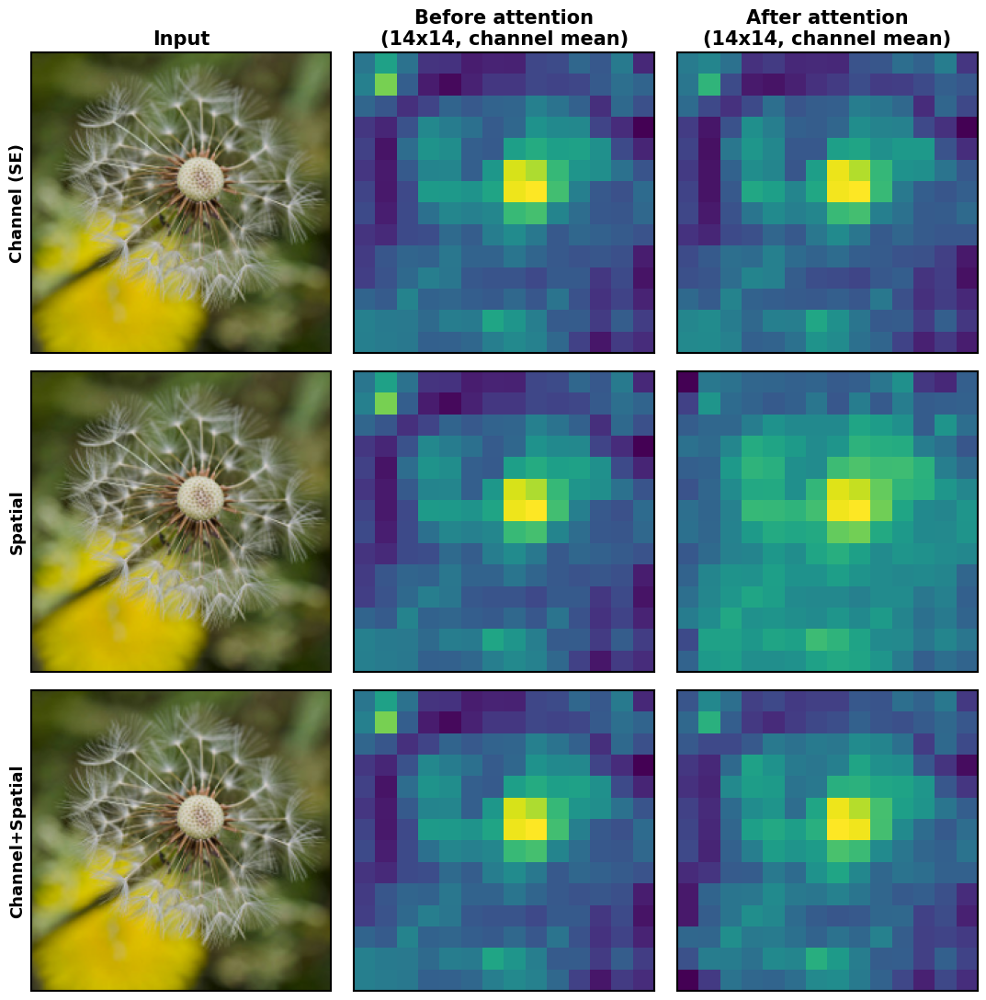

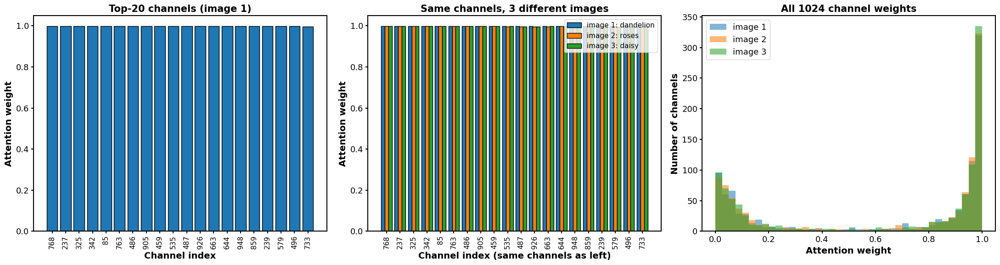

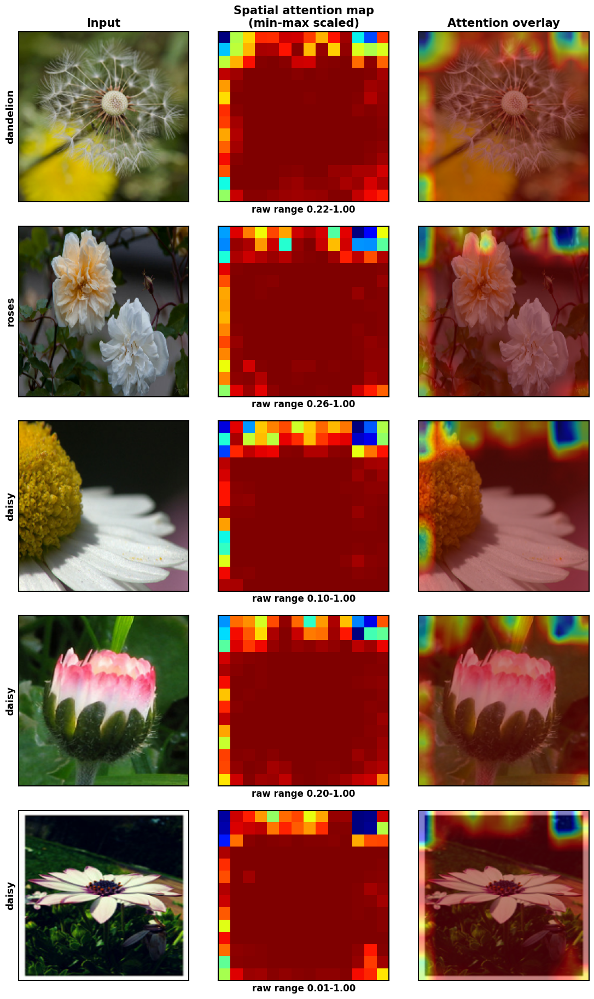

In [21]:
# ----------------------------- plot 10: feature maps before / after attention -----------------------------
rows_m = [('A1', 'Channel (SE)'), ('A2', 'Spatial'), ('A3', 'Channel+Spatial')]
fig, axs = plt.subplots(len(rows_m), 3, figsize=(11, 3.7 * len(rows_m)))
x = prep1(REP)
for r, (k, lab) in enumerate(rows_m):
    pre, post = pre_post(k, 3, x)
    b = norm(pre.numpy()[0].mean(-1)); a = norm(post.numpy()[0].mean(-1))
    axs[r, 0].imshow(X_TEST[REP]); axs[r, 1].imshow(b, cmap='viridis'); axs[r, 2].imshow(a, cmap='viridis')
    axs[r, 0].set_ylabel(lab, fontsize=13)
    for c in range(3):
        axs[r, c].set_xticks([]); axs[r, c].set_yticks([])
axs[0, 0].set_title('Input'); axs[0, 1].set_title('Before attention\n(14x14, channel mean)'); axs[0, 2].set_title('After attention\n(14x14, channel mean)')
plt.tight_layout()
savefig('10_feature_maps_before_after.png')

# ----------------------------- plot 11: channel-attention weights (A1, P3, 1024 channels) -----------------------------
K_TOP = 20
ids3 = QUAL_IDX[:3]
W = []
for i in ids3:
    pre, _ = pre_post('A1', 3, prep1(i))
    W.append(att_layer('A1', 3).maps(pre)['channel'].numpy()[0])
W = np.array(W)
top = np.argsort(-W[0])[:K_TOP]
fig, axs = plt.subplots(1, 3, figsize=(22, 6))
axs[0].bar(range(K_TOP), W[0][top], color='tab:blue', edgecolor='black')
axs[0].set_xticks(range(K_TOP)); axs[0].set_xticklabels(top, rotation=90, fontsize=11)
axs[0].set_xlabel('Channel index'); axs[0].set_ylabel('Attention weight'); axs[0].set_title(f'Top-{K_TOP} channels (image 1)')
wd = 0.27
for j in range(3):
    axs[1].bar(np.arange(K_TOP) + (j - 1) * wd, W[j][top], wd, label=f'image {j + 1}: {CLASS_NAMES[Y_TEST[ids3[j]]]}', edgecolor='black')
axs[1].set_xticks(range(K_TOP)); axs[1].set_xticklabels(top, rotation=90, fontsize=11)
axs[1].set_xlabel('Channel index (same channels as left)'); axs[1].set_ylabel('Attention weight'); axs[1].set_title('Same channels, 3 different images')
axs[1].legend(fontsize=11)
for j in range(3):
    axs[2].hist(W[j], bins=40, alpha=0.55, label=f'image {j + 1}')
axs[2].set_xlabel('Attention weight'); axs[2].set_ylabel('Number of channels'); axs[2].set_title('All 1024 channel weights'); axs[2].legend()
plt.tight_layout()
savefig('11_channel_attention_weights.png')

# ----------------------------- plots 12-13: spatial-attention map and overlay (A2, P3) -----------------------------
fig, axs = plt.subplots(len(QUAL_IDX), 3, figsize=(11.5, 3.7 * len(QUAL_IDX)))
for r, i in enumerate(QUAL_IDX):
    pre, _ = pre_post('A2', 3, prep1(i))
    s = att_layer('A2', 3).maps(pre)['spatial'].numpy()[0]
    axs[r, 0].imshow(X_TEST[i]); axs[r, 1].imshow(norm(s), cmap='jet'); axs[r, 2].imshow(X_TEST[i]); axs[r, 2].imshow(up(norm(s)), cmap='jet', alpha=0.5)
    axs[r, 0].set_ylabel(f'{CLASS_NAMES[Y_TEST[i]]}', fontsize=13)
    axs[r, 1].set_xlabel(f'raw range {s.min():.2f}-{s.max():.2f}', fontsize=12)
    for c in range(3):
        axs[r, c].set_xticks([]); axs[r, c].set_yticks([])
axs[0, 0].set_title('Input'); axs[0, 1].set_title('Spatial attention map\n(min-max scaled)'); axs[0, 2].set_title('Attention overlay')
plt.tight_layout()
savefig('12_spatial_attention_overlay.png')

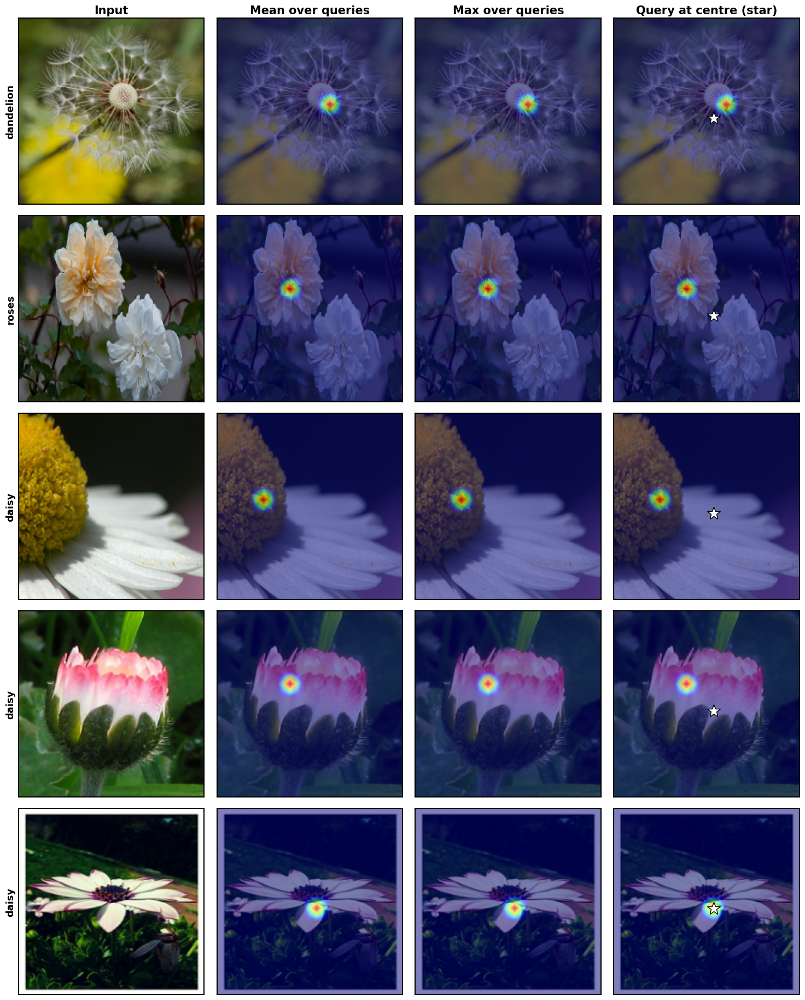

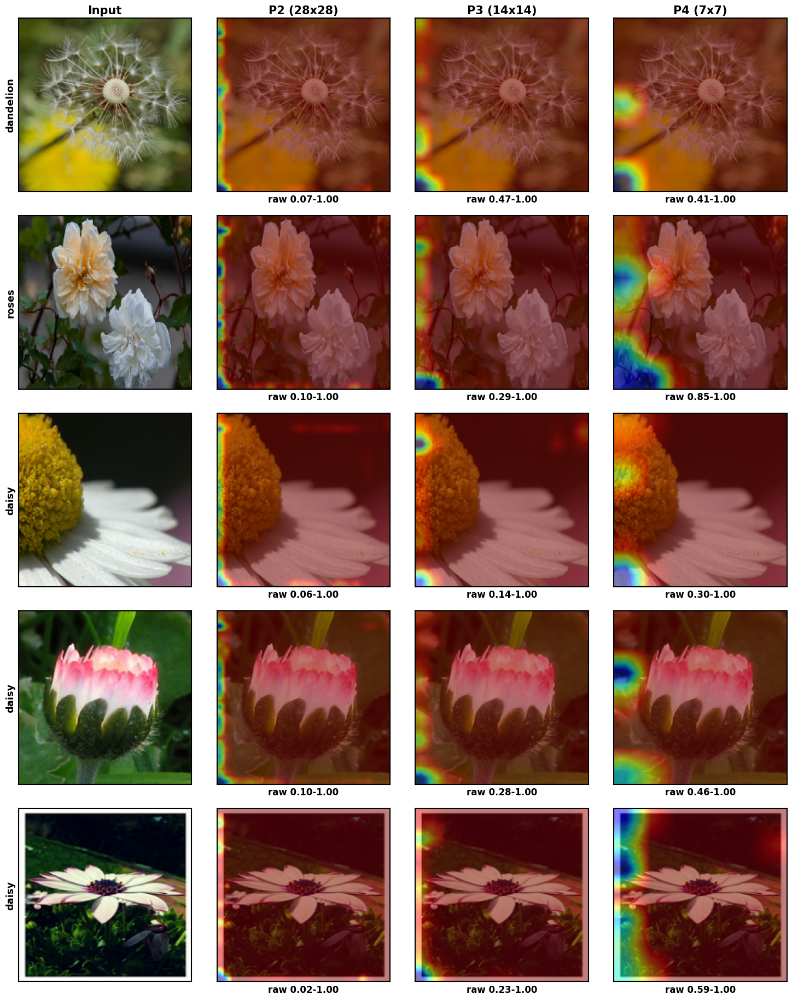

In [22]:
# ----------------------------- plot 14: self-attention response (A4, P3, 14x14 = 196 positions) -----------------------------
Q_POS = (7, 7)   # query location (row, col) on the 14x14 grid
fig, axs = plt.subplots(len(QUAL_IDX), 4, figsize=(15, 3.7 * len(QUAL_IDX)))
for r, i in enumerate(QUAL_IDX):
    pre, _ = pre_post('A4', 3, prep1(i))
    A = att_layer('A4', 3).maps(pre)['attn_matrix'].numpy()[0]            # (196, 196): row = query, col = key
    mean_q = A.mean(0).reshape(14, 14); max_q = A.max(0).reshape(14, 14); one_q = A[Q_POS[0] * 14 + Q_POS[1]].reshape(14, 14)
    axs[r, 0].imshow(X_TEST[i])
    axs[r, 1].imshow(X_TEST[i]); axs[r, 1].imshow(up(norm(mean_q)), cmap='jet', alpha=0.5)
    axs[r, 2].imshow(X_TEST[i]); axs[r, 2].imshow(up(norm(max_q)), cmap='jet', alpha=0.5)
    axs[r, 3].imshow(X_TEST[i]); axs[r, 3].imshow(up(norm(one_q)), cmap='jet', alpha=0.5)
    axs[r, 3].plot(Q_POS[1] * 16 + 8, Q_POS[0] * 16 + 8, marker='*', ms=18, mfc='white', mec='black')
    axs[r, 0].set_ylabel(f'{CLASS_NAMES[Y_TEST[i]]}', fontsize=13)
    for c in range(4):
        axs[r, c].set_xticks([]); axs[r, c].set_yticks([])
axs[0, 0].set_title('Input'); axs[0, 1].set_title('Mean over queries'); axs[0, 2].set_title('Max over queries'); axs[0, 3].set_title('Query at centre (star)')
plt.tight_layout()
savefig('14_self_attention_response.png')

# ----------------------------- plot 15: spatial attention at P2, P3, P4 (Channel->Spatial models B2, A3, B4) -----------------------------
pos_models = [(2, 'B2'), (3, 'A3'), (4, 'B4')]
fig, axs = plt.subplots(len(QUAL_IDX), 4, figsize=(15, 3.7 * len(QUAL_IDX)))
for r, i in enumerate(QUAL_IDX):
    x = prep1(i)
    axs[r, 0].imshow(X_TEST[i]); axs[r, 0].set_ylabel(f'{CLASS_NAMES[Y_TEST[i]]}', fontsize=13)
    for c, (k, key) in enumerate(pos_models, start=1):
        pre, _ = pre_post(key, k, x)
        s = att_layer(key, k).maps(pre)['spatial'].numpy()[0]
        axs[r, c].imshow(X_TEST[i]); axs[r, c].imshow(up(norm(s)), cmap='jet', alpha=0.5)
        axs[r, c].set_xlabel(f'raw {s.min():.2f}-{s.max():.2f}', fontsize=12)
    for c in range(4):
        axs[r, c].set_xticks([]); axs[r, c].set_yticks([])
axs[0, 0].set_title('Input'); axs[0, 1].set_title('P2 (28x28)'); axs[0, 2].set_title('P3 (14x14)'); axs[0, 3].set_title('P4 (7x7)')
plt.tight_layout()
savefig('15_spatial_attention_P2_P3_P4.png')

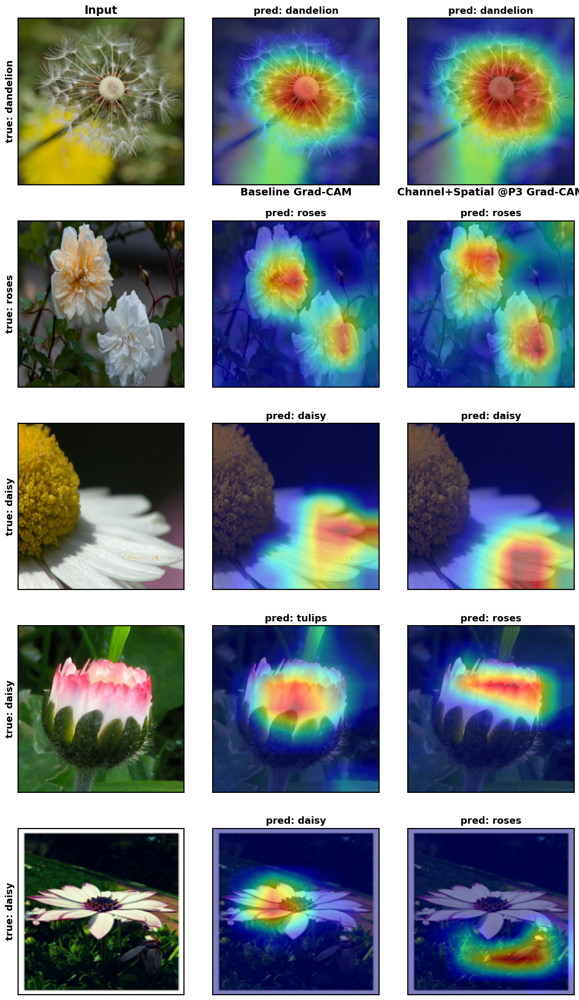

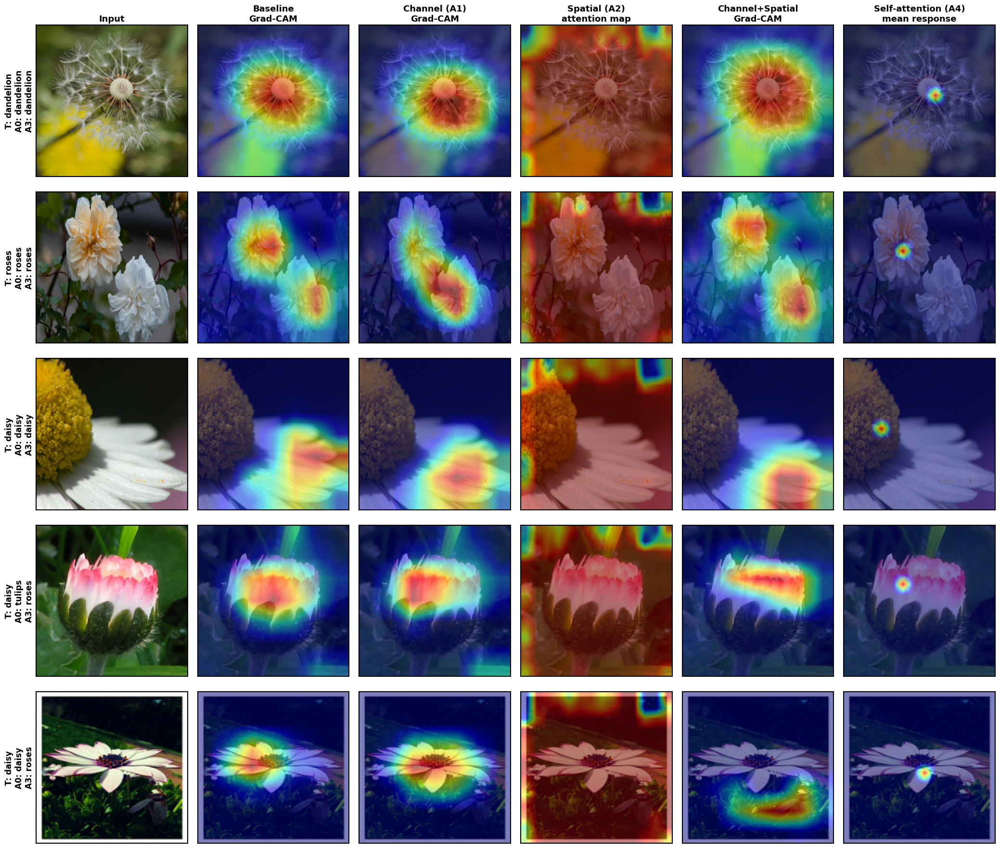

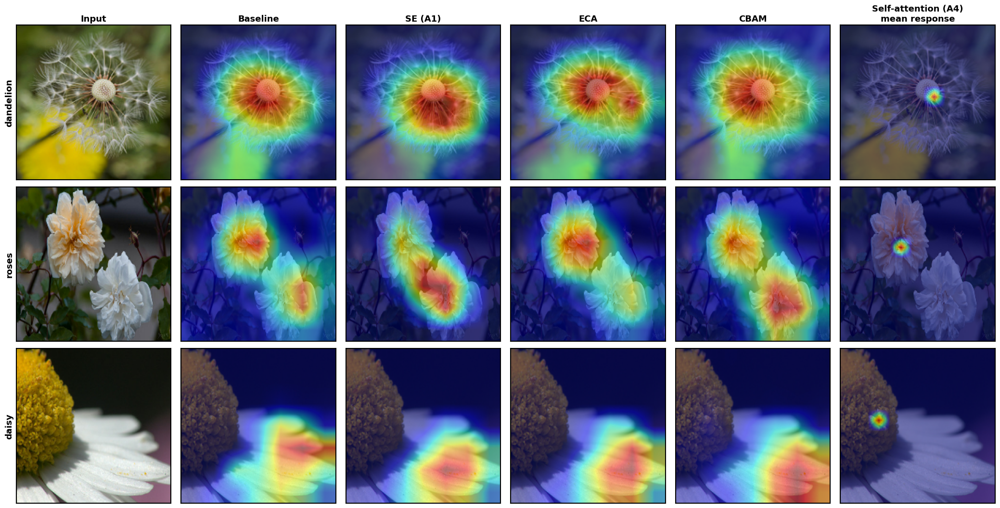

In [23]:
# ----------------------------- plots 16-18: Grad-CAM comparisons -----------------------------
CAM = {}
for key in ['A0', 'A1', 'A3', 'ECA', 'CBAM']:
    for i in QUAL_IDX:
        CAM[(key, i)] = gradcam(key, prep1(i))

# plot 16: Input | Baseline Grad-CAM | Attention-model Grad-CAM (Channel+Spatial @P3)
fig, axs = plt.subplots(len(QUAL_IDX), 3, figsize=(11.5, 3.8 * len(QUAL_IDX)))
for r, i in enumerate(QUAL_IDX):
    axs[r, 0].imshow(X_TEST[i]); axs[r, 0].set_xticks([]); axs[r, 0].set_yticks([])
    axs[r, 0].set_ylabel(f'true: {CLASS_NAMES[Y_TEST[i]]}', fontsize=13)
    for c, key in ((1, 'A0'), (2, 'A3')):
        cam, cls = CAM[(key, i)]
        overlay(axs[r, c], i, cam, f'pred: {CLASS_NAMES[cls]}')
axs[0, 0].set_title('Input'); 
axs[0, 1].set_xlabel('Baseline Grad-CAM'); axs[0, 2].set_xlabel('Channel+Spatial @P3 Grad-CAM')
for c in (1, 2):
    axs[-1, c].xaxis.set_label_position('bottom')
plt.tight_layout()
savefig('16_gradcam_baseline_vs_attention.png')

# plot 17: full qualitative grid (manual Sec. 30): Input | Baseline GC | Channel GC | Spatial map | C+S GC | Self-attention response
fig, axs = plt.subplots(len(QUAL_IDX), 6, figsize=(21, 3.6 * len(QUAL_IDX)))
heads = ['Input', 'Baseline\nGrad-CAM', 'Channel (A1)\nGrad-CAM', 'Spatial (A2)\nattention map', 'Channel+Spatial\nGrad-CAM', 'Self-attention (A4)\nmean response']
for r, i in enumerate(QUAL_IDX):
    x = prep1(i)
    axs[r, 0].imshow(X_TEST[i])
    axs[r, 0].set_ylabel(f'T: {CLASS_NAMES[Y_TEST[i]]}\nA0: {CLASS_NAMES[p0[i]]}\nA3: {CLASS_NAMES[p3[i]]}', fontsize=12)
    overlay(axs[r, 1], i, CAM[('A0', i)][0]); overlay(axs[r, 2], i, CAM[('A1', i)][0]); overlay(axs[r, 4], i, CAM[('A3', i)][0])
    pre, _ = pre_post('A2', 3, x)
    s = att_layer('A2', 3).maps(pre)['spatial'].numpy()[0]
    overlay(axs[r, 3], i, up(norm(s)))
    pre, _ = pre_post('A4', 3, x)
    A = att_layer('A4', 3).maps(pre)['attn_matrix'].numpy()[0]
    overlay(axs[r, 5], i, up(norm(A.mean(0).reshape(14, 14))))
    for c in range(6):
        axs[r, c].set_xticks([]); axs[r, c].set_yticks([])
for c, h in enumerate(heads):
    axs[0, c].set_title(h, fontsize=13)
plt.tight_layout()
savefig('17_qualitative_grid.png')

# plot 18: extended layout (manual Sec. 32): Input | Baseline | SE | ECA | CBAM | Self-attention
fig, axs = plt.subplots(len(correct), 6, figsize=(21, 3.6 * len(correct)))
heads = ['Input', 'Baseline', 'SE (A1)', 'ECA', 'CBAM', 'Self-attention (A4)\nmean response']
for r, i in enumerate(correct):
    axs[r, 0].imshow(X_TEST[i]); axs[r, 0].set_ylabel(CLASS_NAMES[Y_TEST[i]], fontsize=13)
    for c, key in ((1, 'A0'), (2, 'A1'), (3, 'ECA'), (4, 'CBAM')):
        overlay(axs[r, c], i, CAM[(key, i)][0])
    pre, _ = pre_post('A4', 3, prep1(i))
    A = att_layer('A4', 3).maps(pre)['attn_matrix'].numpy()[0]
    overlay(axs[r, 5], i, up(norm(A.mean(0).reshape(14, 14))))
    for c in range(6):
        axs[r, c].set_xticks([]); axs[r, c].set_yticks([])
for c, h in enumerate(heads):
    axs[0, c].set_title(h, fontsize=13)
plt.tight_layout()
savefig('18_gradcam_extended_SE_ECA_CBAM_SA.png')

In [24]:
# ----------------------------- aggregate attention statistics over many test images (avoid single-image conclusions) -----------------------------
rs = np.random.RandomState(SEED)
sample = rs.permutation(len(Y_TEST))[:min(100, len(Y_TEST))]
stats = {'n_images': int(len(sample)), 'spatial': {}, 'channel': {}}
for key, k in (('B2', 2), ('A3', 3), ('B4', 4), ('A2', 3)):
    maps_ = []
    for i in sample:
        pre, _ = pre_post(key, k, prep1(int(i)))
        maps_.append(att_layer(key, k).maps(pre)['spatial'].numpy()[0])
    M = np.array(maps_)
    stats['spatial'][f'{key}_P{k}'] = {'mean': float(M.mean()), 'min': float(M.min()), 'max': float(M.max()),
                                      'within_image_std': float(M.reshape(len(M), -1).std(1).mean()),
                                      'across_image_std_of_mean_map': float(M.mean(0).std()),
                                      'frac_above_0.5': float((M > 0.5).mean())}
for key, k in (('A1', 3), ('A3', 3), ('ECA', 3), ('CBAM', 3)):
    ws = []
    for i in sample:
        pre, _ = pre_post(key, k, prep1(int(i)))
        ws.append(att_layer(key, k).maps(pre)['channel'].numpy()[0])
    Wm = np.array(ws)
    top10 = np.argsort(-Wm.mean(0))[:10]
    stats['channel'][f'{key}_P{k}'] = {'mean': float(Wm.mean()), 'min': float(Wm.min()), 'max': float(Wm.max()),
                                      'frac_channels_above_0.5': float((Wm.mean(0) > 0.5).mean()),
                                      'top10_mean_weight': float(Wm.mean(0)[top10].mean()),
                                      'mean_across_image_std_per_channel': float(Wm.std(0).mean())}
with open(WORK / 'attention_stats.json', 'w') as f:
    json.dump(stats, f, indent=1)
print(json.dumps(stats, indent=1))

{
 "n_images": 100,
 "spatial": {
  "B2_P2": {
   "mean": 0.9781197905540466,
   "min": 0.001614849315956235,
   "max": 1.0,
   "within_image_std": 0.1013687402009964,
   "across_image_std_of_mean_map": 0.09383399784564972,
   "frac_above_0.5": 0.9835969387755102
  },
  "A3_P3": {
   "mean": 0.982854962348938,
   "min": 0.0932028666138649,
   "max": 1.0,
   "within_image_std": 0.07339972257614136,
   "across_image_std_of_mean_map": 0.06651773303747177,
   "frac_above_0.5": 0.9925510204081632
  },
  "B4_P4": {
   "mean": 0.9733699560165405,
   "min": 0.008325682021677494,
   "max": 1.0,
   "within_image_std": 0.11398289352655411,
   "across_image_std_of_mean_map": 0.09187893569469452,
   "frac_above_0.5": 0.9789795918367347
  },
  "A2_P3": {
   "mean": 0.9380995035171509,
   "min": 0.00019749549392145127,
   "max": 1.0,
   "within_image_std": 0.14966554939746857,
   "across_image_std_of_mean_map": 0.13405479490756989,
   "frac_above_0.5": 0.9659183673469388
  }
 },
 "channel": {
  "A1_P

In [25]:
# ----------------------------- final packaging: metrics summary, checklist, zip -----------------------------
summary = {'seed': SEED, 'epochs_frozen': EPOCHS_FROZEN, 'epochs_finetune': EPOCHS_FINETUNE, 'lr_head': LR_HEAD, 'lr_finetune': LR_FINETUNE,
           'batch': BATCH, 'split': {'train': int(len(Y_TRAIN)), 'val': int(len(Y_VAL)), 'test': int(len(Y_TEST))},
           'runs': {k: {kk: vv for kk, vv in r.items() if kk != 'history'} for k, r in RESULTS.items()}}
with open(WORK / 'metrics_summary.json', 'w') as f:
    json.dump(summary, f, indent=1, default=_jsonable)

# checklist against the manual's Sec. 31 required visualizations
REQUIRED = {
    '1 sample images (5 classes)': '01_sample_images.png', '2 accuracy curves': '02_accuracy_curves.png', '3 loss curves': '03_loss_curves.png',
    '4 confusion matrix': '04_confusion_matrices.png', '5 feature map before attention': '10_feature_maps_before_after.png',
    '6 channel-attention weights': '11_channel_attention_weights.png', '7 spatial-attention heatmap': '12_spatial_attention_overlay.png',
    '8 spatial-attention overlay': '12_spatial_attention_overlay.png', '9 self-attention response': '14_self_attention_response.png',
    '10 feature map after attention': '10_feature_maps_before_after.png', '11 baseline Grad-CAM': '16_gradcam_baseline_vs_attention.png',
    '12 attention-model Grad-CAM': '16_gradcam_baseline_vs_attention.png', '13 attention maps P2/P3/P4': '15_spatial_attention_P2_P3_P4.png',
    '14 mechanism comparison graph': '05_bar_accuracy.png'}
for k, v in REQUIRED.items():
    print(('OK      ' if (PLOTS / v).exists() else 'MISSING ') + k + '  ->  ' + v)
print('\nOther plots:', sorted(p.name for p in PLOTS.glob('*.png') if p.name not in set(REQUIRED.values())))

zip_path = WORK / 'plots.zip'
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as z:
    for p in sorted(PLOTS.glob('*.png')):
        z.write(p, arcname='plots/' + p.name)
tz = WORK / 'tables.zip'
with zipfile.ZipFile(tz, 'w', zipfile.ZIP_DEFLATED) as z:
    for p in sorted(TABLES.glob('*.csv')):
        z.write(p, arcname='tables/' + p.name)
print('\nOutputs in', WORK.resolve())
print(' plots.zip     :', len(list(PLOTS.glob("*.png"))), 'figures')
print(' tables.zip, results_summary.csv, metrics_summary.json, attention_stats.json, split_indices.json')
print(' checkpoints/  : per-run weights (.weights.h5), metrics (.json), test logits (.npy)')
total_min = sum(r['train_time_s'] for r in RESULTS.values()) / 60
print(f'Total training time over {len(RESULTS)} runs: {total_min:.1f} min')

OK      1 sample images (5 classes)  ->  01_sample_images.png
OK      2 accuracy curves  ->  02_accuracy_curves.png
OK      3 loss curves  ->  03_loss_curves.png
OK      4 confusion matrix  ->  04_confusion_matrices.png
OK      5 feature map before attention  ->  10_feature_maps_before_after.png
OK      6 channel-attention weights  ->  11_channel_attention_weights.png
OK      7 spatial-attention heatmap  ->  12_spatial_attention_overlay.png
OK      8 spatial-attention overlay  ->  12_spatial_attention_overlay.png
OK      9 self-attention response  ->  14_self_attention_response.png
OK      10 feature map after attention  ->  10_feature_maps_before_after.png
OK      11 baseline Grad-CAM  ->  16_gradcam_baseline_vs_attention.png
OK      12 attention-model Grad-CAM  ->  16_gradcam_baseline_vs_attention.png
OK      13 attention maps P2/P3/P4  ->  15_spatial_attention_P2_P3_P4.png
OK      14 mechanism comparison graph  ->  05_bar_accuracy.png

Other plots: ['06_bar_macro_f1.png', '07_scatte